# **GAN Generator: Creación Condicional de Caras a partir de Máscaras (pix2pix)**

## **0. Fundamento teórico y objetivos**

Este notebook entrena desde cero y evalúa una GAN condicional para crear caras RGB de $64 \times 64$ a partir de las **8 máscaras de segmentación binarias** de nuestro dataset (`hair`, `hat`, `l_ear`, `l_eye`, `mouth`, `nose`, `r_ear`, `r_eye`).

### **0.1 Marco teórico**

1. **GAN condicional y pix2pix:** una red generativa adversarial enfrenta a un **Generador $G$** contra un **Discriminador $D$**. En **pix2pix**, ambas redes reciben las máscaras de entrada:
   - **$G(x)$** transforma la máscara en una cara sintética mediante una **U-Net** con *skip connections* a todas las escalas (`32x32`, `16x16`, `8x8`, `4x4`) más una conexión directa de la máscara original en `64x64`, preservando la posición de las características.
   - **$D(x, y)$** es un **PatchGAN** condicional que recibe $[x, y]$ y devuelve un único mapa de salida $16 \times 16 \times 1$, donde cada celda evalúa un parche local de $34 \times 34$ píxeles (4 convoluciones `k=4` con pasos `2, 2, 1, 1`). Se juzgan parches locales, por lo que se necesitan texturas realistas.

2. **LSGAN:** sustituimos la entropía cruzada por la pérdida de mínimos cuadrados (MSE), suavizando la etiqueta real a $0.9$ para evitar saturación temprana del discriminador y mantener gradientes útiles para $G$. Si no hacemos esto, $D$ aprende demasiado rápido y le es muy fácil detectar si una imagen es real o generada, por lo que $G$ se queda sin gradientes. La pérdida de $D$ y $G$ es:
   $$\mathcal{L}_{D} = \frac{1}{2}\Big[\mathbb{E}_{x,y}\big[(D(x,y) - 0.9)^2\big] + \mathbb{E}_{x}\big[D(x, G(x))^2\big]\Big], \qquad \mathcal{L}_{\text{LSGAN}}(G) = \mathbb{E}_{x}\big[(D(x, G(x)) - 1.0)^2\big]$$

3. **Normalización estable:**
   - En $G$ y $D$ usamos `GroupNormalization(groups=-1)` (*InstanceNorm*), que normaliza cada imagen y canal por separado sin depender de batches. Esto no es una decisión arbitraria, sino que nace de una prueba y error usando **Batch Normalization**, que causaba manchas de color y muchas diferencias de calidad entre entrenamiento e inferencia.
   - En todas las convoluciones de $D$ aplicamos **Spectral Normalization**, que divide la matriz de pesos de cada capa por su **mayor valor singular**, lo que ayuda a acotar las transformaciones y estabilizar la magnitud de los gradientes. Es el estándar para GANs, ya que evita que $D$ aprenda demasiado rápido.
4. **Pérdida de 3 términos (`LSGAN + L1 + VGG16`):**
   $$\mathcal{L}_{G} = \lambda_{\text{GAN}}\,\mathcal{L}_{\text{LSGAN}}(G) + \lambda_{L1}\,\mathbb{E}_{x,y}\big[\|y - G(x)\|_1\big] + \lambda_{\text{perc}}\,\mathcal{L}_{\text{VGG16}}(y, G(x))$$
   - **Punto de partida (`GAN + L1`):** la pérdida estándar de **pix2pix** combina el término adversarial con el error `L1` píxel a píxel. `L1` penaliza desviaciones por píxel, por lo que tiende a promediar las frecuencias y producir caras suavizadas o borrosas.
   - **Añadimos `VGG16`:** la pérdida perceptual compara activaciones intermedias (`block2_conv2` y `block3_conv3`) de una VGG16 congelada, penalizando diferencias en rasgos y texturas de medio nivel para mejorar la nitidez sin añadir coste en inferencia.
   - **El término `GAN` ocupa solo ~3%–10% del valor escalar total:** la pérdida adversarial tiene gradientes con magnitud escalar mucho mayor que los de `L1` o `VGG16`. Si la magnitud escalar dominara la suma, desestabilizaría el generador. De forma natural, `L1 + VGG16` actúan como un factor que mantiene la estructura y el color. La métrica `1 - SSIM` se utiliza para evaluación por falta de recursos computacionales para ver si los resultados mejorarían.

5. **Entrenamiento y evaluación:**
   - Antes del entrenamiento final realizamos una comparativa de **3 configuraciones de pesos** durante `10` epochs, eligiendo la resultante por su mejor **Fréchet Inception Distance (FID)** en validación (`val_fid` sobre `500` caras con características reales cacheadas por optimización).
   - Con estos pesos entrenamos el modelo final durante **`30` epochs** completas con `CosineDecay`, manteniendo al final los pesos con menor `val_fid`.
   - En la evaluación final medimos el rendimiento sobre las **`3.000` muestras de `test`**.

---

## **1. Configuración e imports**

In [18]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import json
import random
import time
from pathlib import Path

import keras
from keras import layers
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import torch
from torchmetrics.image.fid import NoTrainInceptionV3, _compute_fid

try:
    from IPython.display import display
except ImportError:
    display = print

tf.get_logger().setLevel("ERROR")

In [ ]:
SEED = 1234
IMG_SIZE = 64
CHANNELS = 3
BATCH_SIZE = 64
ABLATION_EPOCHS = 10
EPOCHS = 30

ABLATION_CONFIGS = [
    {"name": "Reconstrucción", "lambda_gan": 1.0, "lambda_l1": 50.0, "lambda_perc": 0.04},
    {"name": "Equilibrado", "lambda_gan": 2.5, "lambda_l1": 30.0, "lambda_perc": 0.05},
    {"name": "Perceptual + GAN", "lambda_gan": 3.0, "lambda_l1": 20.0, "lambda_perc": 0.08},
]

# Valores iniciales (se actualizan con la mejor configuración)
LAMBDA_GAN = 2.5
LAMBDA_L1 = 30.0
LAMBDA_PERC = 0.05

REAL_LABEL_SMOOTH = 0.9
G_LR_INIT = 2e-4
D_LR_INIT = 1e-4
COSINE_ALPHA = 0.05
BETA_1 = 0.5

VAL_FID_SAMPLES = 500
VAL_FID_EVERY = 2
FID_BATCH_SIZE = 64
NEW_FACES_N = 3000

TRAIN_MODEL = False  # Cambiar a False para no reentrenar
NOTEBOOK_NAME = "gan_generator"

DATA_DIR = Path("data")
IMAGES_DIR = DATA_DIR / "images"
MASKS_DIR = DATA_DIR / "masks"

if not IMAGES_DIR.is_dir() or not MASKS_DIR.is_dir():
    raise FileNotFoundError(
        f"Faltan los directorios requeridos en {DATA_DIR.resolve()} (se esperan 'images/' y 'masks/')."
    )

CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

GENERATOR_PATH = CHECKPOINT_DIR / "generator_gan.keras"
DISCRIMINATOR_PATH = CHECKPOINT_DIR / "discriminator_gan.keras"
MASK_CLASSES_PATH = CHECKPOINT_DIR / "mask_classes_gan.json"
ABLATION_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_ablation.json"
HISTORY_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_history.json"
VAL_EVOLUTION_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_val_evolution.npz"
METRICS_CSV_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_metrics.csv"


def reset_seeds(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    torch.manual_seed(seed)


reset_seeds(SEED)

print(f"Imágenes: {IMAGES_DIR.resolve()}")
print(f"Máscaras: {MASKS_DIR.resolve()}")
print(f"Checkpoints: {CHECKPOINT_DIR.resolve()}")
print(f"TRAIN_MODEL={TRAIN_MODEL} | Comparativa={ABLATION_EPOCHS} ep | Final={EPOCHS} ep")

Imágenes: /Users/dani22/Desktop/MetodosGenerativos/masks-to-faces-generator/data/images
Máscaras: /Users/dani22/Desktop/MetodosGenerativos/masks-to-faces-generator/data/masks
Checkpoints: /Users/dani22/Desktop/MetodosGenerativos/masks-to-faces-generator/checkpoints
TRAIN_MODEL=True | Comparativa=10 ep | Final=30 ep


In [20]:
gpus = tf.config.list_physical_devices("GPU")
INCEPTION_DEVICE = (
    "cuda" if torch.cuda.is_available()
    else ("mps" if torch.backends.mps.is_available() else "cpu")
)
print(f"TensorFlow: {gpus if gpus else 'CPU'} | InceptionV3 (PyTorch): {INCEPTION_DEVICE}")

TensorFlow: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | InceptionV3 (PyTorch): mps


---

## **2. Carga de datos y máscaras One-Hot**

In [21]:
mask_filenames = sorted(p.name for p in MASKS_DIR.iterdir() if p.suffix.lower() == ".png")
if not mask_filenames:
    raise FileNotFoundError(f"No hay archivos PNG en {MASKS_DIR.resolve()}")

available_mask_files = set(mask_filenames)
attr_counts = {}
for fname in mask_filenames:
    stem = fname[:-4]
    if "_" not in stem:
        continue
    _, attr_name = stem.split("_", 1)
    attr_counts[attr_name] = attr_counts.get(attr_name, 0) + 1

MASK_CLASSES = sorted(attr_counts.keys())
NUM_CLASSES = len(MASK_CLASSES)

if TRAIN_MODEL or not MASK_CLASSES_PATH.exists():
    MASK_CLASSES_PATH.write_text(json.dumps(MASK_CLASSES, indent=2, ensure_ascii=False))
else:
    saved_classes = json.loads(MASK_CLASSES_PATH.read_text())
    if saved_classes != MASK_CLASSES:
        raise ValueError("Las clases guardadas en mask_classes_gan.json no coinciden con las detectadas.")

print(f"Clases detectadas (C = {NUM_CLASSES}): {MASK_CLASSES}")
for cls_name in MASK_CLASSES:
    print(f"- {cls_name}: {attr_counts[cls_name]} máscaras")

Clases detectadas (C = 8): ['hair', 'hat', 'l_ear', 'l_eye', 'mouth', 'nose', 'r_ear', 'r_eye']
- hair: 29300 máscaras
- hat: 1284 máscaras
- l_ear: 15868 máscaras
- l_eye: 29258 máscaras
- mouth: 17663 máscaras
- nose: 29998 máscaras
- r_ear: 14326 máscaras
- r_eye: 29260 máscaras


In [22]:
def _sort_image_key(path: Path):
    return (0, int(path.stem)) if path.stem.isdigit() else (1, path.stem)

def _resolve_mask_prefix(image_stem: str) -> str:
    return f"{int(image_stem):05d}" if image_stem.isdigit() else image_stem

image_paths = sorted(
    (p for p in IMAGES_DIR.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}),
    key=_sort_image_key,
)
if not image_paths:
    raise FileNotFoundError(f"No hay imágenes en {IMAGES_DIR.resolve()}")

records = [(p.stem, _resolve_mask_prefix(p.stem), p) for p in image_paths]
total_samples = len(records)

perm_indices = np.random.default_rng(SEED).permutation(total_samples)
n_train = int(0.80 * total_samples)
n_val = int(0.10 * total_samples)

train_records = [records[i] for i in perm_indices[:n_train]]
val_records = [records[i] for i in perm_indices[n_train:n_train + n_val]]
test_records = [records[i] for i in perm_indices[n_train + n_val:]]

print(f"Total: {total_samples} | train: {len(train_records)} | val: {len(val_records)} | test: {len(test_records)}")

Total: 30000 | train: 24000 | val: 3000 | test: 3000


In [23]:
def load_real_image(image_path: Path, img_size: int = IMG_SIZE, normalize: bool = True) -> np.ndarray:
    """Carga una cara RGB (img_size, img_size, 3) en uint8 [0, 255] o float32 [-1.0, 1.0]."""
    img = keras.utils.load_img(
        image_path, color_mode="rgb", target_size=(img_size, img_size), interpolation="bilinear"
    )
    arr = keras.utils.img_to_array(img, dtype="float32" if normalize else "uint8")
    return (arr / 127.5) - 1.0 if normalize else arr


def load_mask_tensor(
    mask_prefix: str,
    mask_classes: list[str] = MASK_CLASSES,
    img_size: int = IMG_SIZE,
    as_uint8: bool = False,
) -> np.ndarray:
    """Construye el tensor binario One-Hot (img_size, img_size, C) en {0, 1}."""
    dtype = np.uint8 if as_uint8 else np.float32
    mask_tensor = np.zeros((img_size, img_size, len(mask_classes)), dtype=dtype)
    for c_idx, cls_name in enumerate(mask_classes):
        fname = f"{mask_prefix}_{cls_name}.png"
        if fname in available_mask_files:
            m_img = keras.utils.load_img(
                MASKS_DIR / fname, color_mode="grayscale", target_size=(img_size, img_size), interpolation="nearest"
            )
            m_arr = keras.utils.img_to_array(m_img, dtype="uint8")[:, :, 0]
            mask_tensor[:, :, c_idx] = (m_arr > 127).astype(dtype)
    return mask_tensor


def load_split_arrays(split_records, as_uint8: bool = False):
    """Carga un subconjunto de pares (máscara, cara) con sus IDs."""
    dtype = np.uint8 if as_uint8 else np.float32
    n = len(split_records)
    x_arr = np.zeros((n, IMG_SIZE, IMG_SIZE, NUM_CLASSES), dtype=dtype)
    y_arr = np.zeros((n, IMG_SIZE, IMG_SIZE, CHANNELS), dtype=dtype)
    ids = np.array([img_id for img_id, _, _ in split_records])

    for idx, (_, mask_prefix, img_path) in enumerate(split_records):
        x_arr[idx] = load_mask_tensor(mask_prefix, as_uint8=as_uint8)
        y_arr[idx] = load_real_image(img_path, normalize=not as_uint8)
    return x_arr, y_arr, ids


x_val, y_val, ids_val = load_split_arrays(val_records, as_uint8=False)
x_test, y_test, ids_test = load_split_arrays(test_records, as_uint8=False)

if TRAIN_MODEL:
    x_train_u8, y_train_u8, _ = load_split_arrays(train_records, as_uint8=True)
    print(f"train: x={x_train_u8.shape}, y={y_train_u8.shape}")

print(f"val: x={x_val.shape}, y={y_val.shape} | rango y=[{y_val.min():.2f}, {y_val.max():.2f}]")
print(f"test: x={x_test.shape}, y={y_test.shape} | rango y=[{y_test.min():.2f}, {y_test.max():.2f}]")

train: x=(24000, 64, 64, 8), y=(24000, 64, 64, 3)
val: x=(3000, 64, 64, 8), y=(3000, 64, 64, 3) | rango y=[-1.00, 1.00]
test: x=(3000, 64, 64, 8), y=(3000, 64, 64, 3) | rango y=[-1.00, 1.00]


In [24]:
PALETTE_MAP = {
    "hair":  (0.40, 0.25, 0.65),
    "hat":   (0.95, 0.75, 0.20),
    "l_ear": (0.15, 0.70, 0.80),
    "r_ear": (0.10, 0.50, 0.65),
    "l_eye": (0.20, 0.85, 0.40),
    "r_eye": (0.55, 0.85, 0.25),
    "nose":  (0.95, 0.50, 0.20),
    "mouth": (0.95, 0.20, 0.30),
}
LAYER_PRIORITY = ["hair", "l_ear", "r_ear", "hat", "nose", "l_eye", "r_eye", "mouth"]
BACKGROUND_COLOR = np.array([0.08, 0.10, 0.14], dtype=np.float32)


def get_class_color(cls_name: str, index: int = 0) -> np.ndarray:
    if cls_name in PALETTE_MAP:
        return np.array(PALETTE_MAP[cls_name], dtype=np.float32)
    return np.array(plt.get_cmap("tab20")(index % 20)[:3], dtype=np.float32)


def colorize_mask(mask_tensor: np.ndarray, mask_classes: list[str] = MASK_CLASSES) -> np.ndarray:
    h, w, _ = mask_tensor.shape
    canvas = np.broadcast_to(BACKGROUND_COLOR, (h, w, 3)).copy()
    ordered = [c for c in LAYER_PRIORITY if c in mask_classes] + [c for c in mask_classes if c not in LAYER_PRIORITY]
    for cls_name in ordered:
        c_idx = mask_classes.index(cls_name)
        active = mask_tensor[:, :, c_idx] > 0.5
        if np.any(active):
            canvas[active] = get_class_color(cls_name, c_idx)
    return canvas


def denormalize_image(img: np.ndarray) -> np.ndarray:
    return np.clip((img + 1.0) * 0.5, 0.0, 1.0)

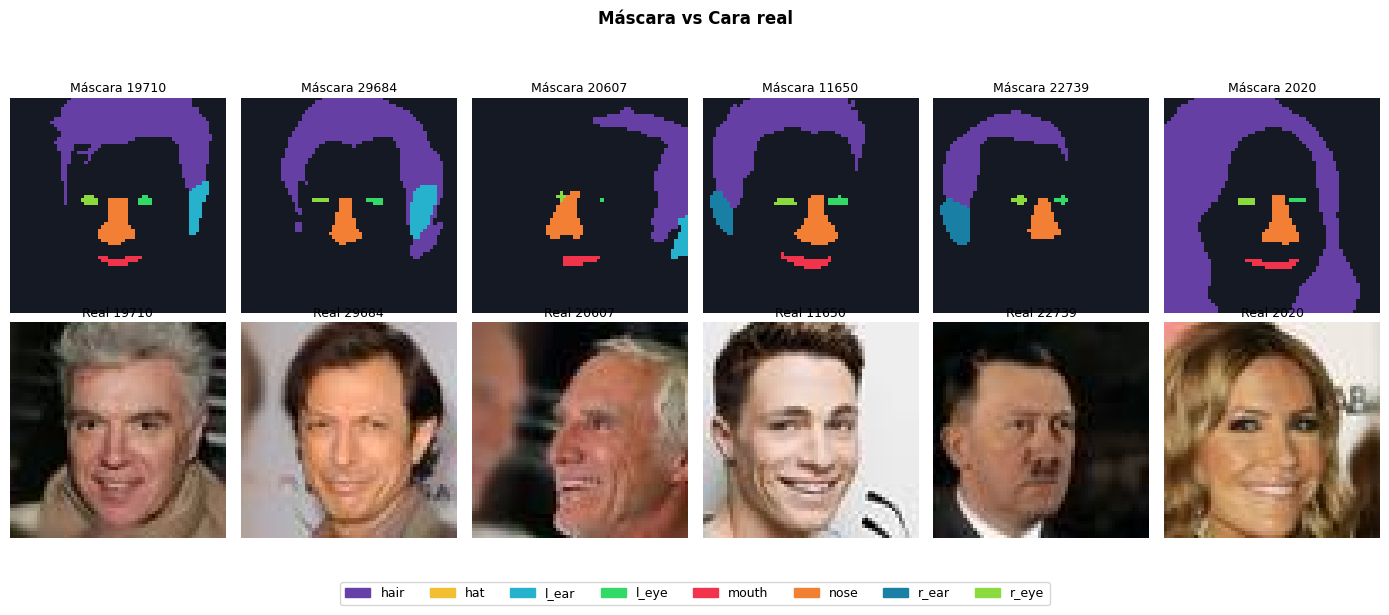

In [25]:
eda_indices = np.random.default_rng(SEED).choice(len(x_val), size=6, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(14, 6.2))
for col_idx, val_idx in enumerate(eda_indices):
    axes[0, col_idx].imshow(colorize_mask(x_val[val_idx]))
    axes[0, col_idx].set_title(f"Máscara {ids_val[val_idx]}", fontsize=9, pad=4)
    axes[0, col_idx].axis("off")

    axes[1, col_idx].imshow(denormalize_image(y_val[val_idx]))
    axes[1, col_idx].set_title(f"Real {ids_val[val_idx]}", fontsize=9, pad=4)
    axes[1, col_idx].axis("off")

legend_handles = [
    mpatches.Patch(color=get_class_color(cls_name, idx), label=cls_name)
    for idx, cls_name in enumerate(MASK_CLASSES)
]
fig.legend(handles=legend_handles, loc="lower center", ncol=NUM_CLASSES, frameon=True, fontsize=9, bbox_to_anchor=(0.5, 0.01))
plt.suptitle("Máscara vs Cara real", fontsize=12, fontweight="bold")
plt.tight_layout(rect=[0, 0.08, 1, 0.94], h_pad=1.8)
plt.show()

---

## **3. Arquitectura: Generador U-Net y Discriminador PatchGAN**

- **Generador ($G$) — U-Net `64x64`:**
  - *Encoder* (`64->32->16->8->4->2`): 5 bloques `Conv2D(4, strides=2)` (`64 -> 128 -> 256 -> 512 -> 512`) con `GroupNormalization(groups=-1)` (*InstanceNorm*) a partir del segundo bloque y `LeakyReLU(0.2)`.
  - *Decoder* (`2->4->8->16->32->64`): bloques `UpSampling2D("bilinear") -> Conv2D(3) -> GroupNormalization(groups=-1) -> [Dropout(0.2) solo en 4x4] -> ReLU -> Concatenate(skip)`.
  - Conexión *skip* directa desde `mask_input` en `64x64` antes de la convolución final y la salida `Conv2D(3, kernel_size=3, activation="tanh")`, manteniendo bordes definidos en ojos, boca, nariz y pelo.
- **Discriminador ($D$) — PatchGAN `16x16`:**
  - Concatena máscara y cara `[x, y]` y aplica 3 bloques convolucionales (`64 -> 128 -> 256`, `k=4`, pasos `2, 2, 1`) con `SpectralNormalization`, `GroupNormalization(groups=-1)` (en los bloques 2 y 3) y `LeakyReLU(0.2)`, seguidos de una 4.ª convolución de salida `Conv2D(1, kernel_size=4, strides=1)` con `SpectralNormalization` que devuelve el mapa `patch_logits` de forma `(16, 16, 1)`.

In [ ]:
def build_generator(num_classes: int = NUM_CLASSES, name: str = "pix2pix_generator_unet") -> keras.Model:
    w_init = keras.initializers.RandomNormal(mean=0.0, stddev=0.02, seed=SEED)
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, num_classes), name="mask_input")

    skips, x = [], inputs
    for idx, filters in enumerate((64, 128, 256, 512, 512)):
        x = layers.Conv2D(
            filters, kernel_size=4, strides=2, padding="same",
            use_bias=False, kernel_initializer=w_init, name=f"enc_conv_{idx + 1}"
        )(x)
        if idx > 0:
            x = layers.GroupNormalization(groups=-1, name=f"enc_in_{idx + 1}")(x)
        x = layers.LeakyReLU(negative_slope=0.2, name=f"enc_lrelu_{idx + 1}")(x)
        skips.append(x)

    x = skips[-1]
    decoder_specs = [(512, True), (256, False), (128, False), (64, False)]
    for idx, ((filters, use_dropout), skip_feat) in enumerate(zip(decoder_specs, reversed(skips[:-1]))):
        x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear", name=f"dec_up_{idx + 1}")(x)
        x = layers.Conv2D(
            filters, kernel_size=3, padding="same",
            use_bias=False, kernel_initializer=w_init, name=f"dec_conv_{idx + 1}"
        )(x)
        x = layers.GroupNormalization(groups=-1, name=f"dec_in_{idx + 1}")(x)
        if use_dropout:
            x = layers.Dropout(0.2, seed=SEED + idx, name=f"dec_drop_{idx + 1}")(x)
        x = layers.ReLU(name=f"dec_relu_{idx + 1}")(x)
        x = layers.Concatenate(axis=-1, name=f"dec_skip_{idx + 1}")([x, skip_feat])

    x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear", name="dec_up_5")(x)
    x = layers.Concatenate(axis=-1, name="dec_skip_input")([x, inputs])
    x = layers.Conv2D(
        64, kernel_size=3, padding="same",
        use_bias=False, kernel_initializer=w_init, name="dec_conv_5"
    )(x)
    x = layers.GroupNormalization(groups=-1, name="dec_in_5")(x)
    x = layers.ReLU(name="dec_relu_5")(x)

    outputs = layers.Conv2D(
        CHANNELS, kernel_size=3, padding="same", activation="tanh",
        kernel_initializer=w_init, name="generator_output"
    )(x)
    return keras.Model(inputs=inputs, outputs=outputs, name=name)


generator = build_generator(NUM_CLASSES)
generator.summary()

Model: "pix2pix_generator_unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ mask_input          │ (None, 64, 64, 8) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_conv_1 (Conv2D) │ (None, 32, 32,    │      8,192 │ mask_input[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_lrelu_1         │ (None, 32, 32,    │          0 │ enc_conv_1[0][0]  │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_conv_2 (Conv2D) │ (None, 16, 16,    │    131,072 │ enc_lrelu_1[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_in_2            │ (None, 16, 16,    │        256 │ enc_conv_2[0][0]  │
│ (GroupNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_lrelu_2         │ (None, 16, 16,    │          0 │ enc_in_2[0][0]    │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_conv_3 (Conv2D) │ (None, 8, 8, 256) │    524,288 │ enc_lrelu_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_in_3            │ (None, 8, 8, 256) │        512 │ enc_conv_3[0][0]  │
│ (GroupNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_lrelu_3         │ (None, 8, 8, 256) │          0 │ enc_in_3[0][0]    │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_conv_4 (Conv2D) │ (None, 4, 4, 512) │  2,097,152 │ enc_lrelu_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_in_4            │ (None, 4, 4, 512) │      1,024 │ enc_conv_4[0][0]  │
│ (GroupNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_lrelu_4         │ (None, 4, 4, 512) │          0 │ enc_in_4[0][0]    │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_conv_5 (Conv2D) │ (None, 2, 2, 512) │  4,194,304 │ enc_lrelu_4[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_in_5            │ (None, 2, 2, 512) │      1,024 │ enc_conv_5[0][0]  │
│ (GroupNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_lrelu_5         │ (None, 2, 2, 512) │          0 │ enc_in_5[0][0]    │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_up_1            │ (None, 4, 4, 512) │          0 │ enc_lrelu_5[0][0] │
│ (UpSampling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_conv_1 (Conv2D) │ (None, 4, 4, 512) │  2,359,296 │ dec_up_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_in_1            │ (None, 4, 4, 512) │      1,024 │ dec_conv_1[0][0]  │
│ (GroupNormalizatio… │                   │            │                 

 Total params: 12,495,811 (47.67 MB)

 Trainable params: 12,495,811 (47.67 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def build_discriminator(num_classes: int = NUM_CLASSES) -> keras.Model:
    w_init = keras.initializers.RandomNormal(mean=0.0, stddev=0.02, seed=SEED)
    mask_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, num_classes), name="disc_mask_input")
    image_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="disc_image_input")
    x = layers.Concatenate(axis=-1, name="disc_concat")([mask_input, image_input])

    for idx, (filters, stride, use_norm) in enumerate([(64, 2, False), (128, 2, True), (256, 1, True)]):
        conv = layers.Conv2D(
            filters, kernel_size=4, strides=stride, padding="same",
            use_bias=not use_norm, kernel_initializer=w_init, name=f"disc_conv_{idx + 1}"
        )
        x = layers.SpectralNormalization(conv, name=f"disc_sn_{idx + 1}")(x)
        if use_norm:
            x = layers.GroupNormalization(groups=-1, name=f"disc_in_{idx + 1}")(x)
        x = layers.LeakyReLU(negative_slope=0.2, name=f"disc_lrelu_{idx + 1}")(x)

    out_conv = layers.Conv2D(
        1, kernel_size=4, strides=1, padding="same",
        kernel_initializer=w_init, name="patch_logits"
    )
    patch_logits = layers.SpectralNormalization(out_conv, name="disc_sn_out")(x)
    return keras.Model(
        inputs=[mask_input, image_input],
        outputs=patch_logits,
        name="pix2pix_patchgan_discriminator",
    )


discriminator = build_discriminator(NUM_CLASSES)
discriminator.summary()

Model: "pix2pix_patchgan_discriminator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ disc_mask_input     │ (None, 64, 64, 8) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ disc_image_input    │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ disc_concat         │ (None, 64, 64,    │          0 │ disc_mask_input[… │
│ (Concatenate)       │ 11)               │            │ disc_image_input… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ disc_sn_1           │ (None, 32, 32,    │     11,392 │ disc_concat[0][0] │
│ (SpectralNormaliza… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ disc_lrelu_1        │ (None, 32, 32,    │          0 │ disc_sn_1[0][0]   │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ disc_sn_2           │ (None, 16, 16,    │    131,200 │ disc_lrelu_1[0][… │
│ (SpectralNormaliza… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ disc_in_2           │ (None, 16, 16,    │        256 │ disc_sn_2[0][0]   │
│ (GroupNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ disc_lrelu_2        │ (None, 16, 16,    │          0 │ disc_in_2[0][0]   │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ disc_sn_3           │ (None, 16, 16,    │    524,544 │ disc_lrelu_2[0][… │
│ (SpectralNormaliza… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ disc_in_3           │ (None, 16, 16,    │        512 │ disc_sn_3[0][0]   │
│ (GroupNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ disc_lrelu_3        │ (None, 16, 16,    │          0 │ disc_in_3[0][0]   │
│ (LeakyReLU)         │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ disc_sn_out         │ (None, 16, 16, 1) │      4,098 │ disc_lrelu_3[0][… │
│ (SpectralNormaliza… │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 672,002 (2.56 MB)

 Trainable params: 671,553 (2.56 MB)

 Non-trainable params: 449 (1.75 KB)

#### **Elección de kernels: `4x4` en el *encoder* y `3x3` en el *decoder***

La diferencia en el tamaño de los filtros entre ambas mitades de la U-Net responde a cómo cambia la resolución en cada paso (`strides=2` al bajar frente a `strides=1` al subir) y combina ideas de la **U-Net** original con mejoras posteriores de **DCGAN** y **pix2pix**:

* **Kernels `4x4` con `strides=2` en el *encoder*:** en lugar de usar `MaxPooling2D` como la U-Net original, la reducción de resolución la hace la propia convolucion con paso 2 (como en DCGAN y pix2pix). Al avanzar de 2 en 2, el filtro `4x4` solapa 2 píxeles en cada eje de forma intencionada:
  * Como el tamaño del kernel (`4`) es divisible por el *stride* (`2`), todos los píxeles interiores se leen el mismo número de veces, evitando el sesgo asimétrico que produciría un `3x3` con `strides=2` (habría píxeles que se leerían una sola vez y otros dos veces, dándoles más peso) y la falta de contexto entre bordes de un `2x2` (no se solapa nada y las convoluciones no estarían interconectadas).

* **Kernels `3x3` con `strides=1` en el *decoder*:** para evitar los problemas de cuadrícula habituales en `Conv2DTranspose(4x4, strides=2)`, escalamos primero con `UpSampling2D("bilinear")` y refinamos después con una convolución normal (`strides=1`):
  * Al usar `strides=1`, un kernel impar (`3x3`) tiene un píxel central exacto y relleno simétrico (`padding="same"` añade 1 píxel a cada lado), manteniendo alineadas las *skip connections* sin el desplazamiento de medio píxel que introduciría un kernel par (`4x4`).
  * Además, es más ligero: cada filtro `3x3` tiene 9 pesos por canal frente a los 16 de un `4x4`, reduciendo los parámetros.

In [ ]:
def generate(masks: np.ndarray) -> np.ndarray:
    if masks.ndim == 3:
        return generator.predict(masks[None, ...], batch_size=BATCH_SIZE, verbose=0)[0]
    return generator.predict(masks, batch_size=BATCH_SIZE, verbose=0)

---

## **4. Pérdidas (`LSGAN + L1 + VGG16`), optimizadores y motor FID**

Partimos de la pérdida clásica de **pix2pix** (`GAN + L1`) y añadimos la pérdida de **VGG16** para ganar nitidez en rasgos faciales sin los suavizados típicos de `L1`:

- **LSGAN (`lambda_gan`):** señal en mínimos cuadrados sobre el mapa `16x16` de $D$ (objetivo real `0.9`, falso `0.0`). Aunque su valor es apenas un **~3%–10%** de la pérdida total, sus gradientes son mucho más bruscos que los de `L1` y `VGG16`; mantenerlo en esa proporción permite que `L1 + VGG16` estabilicen un resultado físicamente real mientras `LSGAN` aporta detalles.
- **Error L1 (`lambda_l1`):** distancia media absoluta píxel a píxel respecto a la cara real.
- **Perceptual VGG16 (`lambda_perc`):** distancia `L1` en `block2_conv2` y `block3_conv3` de VGG16 congelada.

Comparamos 3 combinaciones de pesos (`Reconstrucción`, `Equilibrado` y `Perceptual + GAN`) durante `10` epochs con `CosineDecay` (`G_lr = 2e-4`, `D_lr = 1e-4`, `alpha = 0.05`) y entrenamos `30` epochs con la configuración que consiga menor `val_fid`. Definimos aquí también **InceptionV3 de `torchmetrics`** (`NoTrainInceptionV3`) para cachear las características reales de validación (`500` caras) y calcular el FID en `float64`.

In [29]:
_vgg = keras.applications.VGG16(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, CHANNELS))
_vgg.trainable = False
perceptual_extractor = keras.Model(
    inputs=_vgg.input,
    outputs=[_vgg.get_layer("block2_conv2").output, _vgg.get_layer("block3_conv3").output],
    name="vgg16_perceptual_extractor",
)


def perceptual_loss(target: tf.Tensor, gen_output: tf.Tensor) -> tf.Tensor:
    t_feats = perceptual_extractor(keras.applications.vgg16.preprocess_input((target + 1.0) * 127.5), training=False)
    g_feats = perceptual_extractor(keras.applications.vgg16.preprocess_input((gen_output + 1.0) * 127.5), training=False)
    return sum(tf.reduce_mean(tf.abs(a - b)) for a, b in zip(t_feats, g_feats)) / len(t_feats)


def discriminator_loss(
    disc_real_logits: tf.Tensor,
    disc_fake_logits: tf.Tensor,
    real_label: float = REAL_LABEL_SMOOTH,
) -> tf.Tensor:
    real_loss = tf.reduce_mean(tf.square(disc_real_logits - real_label))
    fake_loss = tf.reduce_mean(tf.square(disc_fake_logits))
    return 0.5 * (real_loss + fake_loss)


def generator_loss(
    disc_fake_logits: tf.Tensor,
    gen_output: tf.Tensor,
    target: tf.Tensor,
    lam_gan: float = LAMBDA_GAN,
    lam_l1: float = LAMBDA_L1,
    lam_perc: float = LAMBDA_PERC,
) -> tuple[tf.Tensor, tf.Tensor, tf.Tensor, tf.Tensor]:
    gan_loss = tf.reduce_mean(tf.square(disc_fake_logits - 1.0))
    l1_loss = tf.reduce_mean(tf.abs(target - gen_output))
    p_loss = perceptual_loss(target, gen_output)
    total = lam_gan * gan_loss + lam_l1 * l1_loss + lam_perc * p_loss
    return total, gan_loss, l1_loss, p_loss


steps_per_epoch = int(np.ceil(len(train_records) / BATCH_SIZE))


def make_optimizers(num_epochs: int) -> tuple[keras.optimizers.Optimizer, keras.optimizers.Optimizer]:
    total_steps = num_epochs * steps_per_epoch
    g_schedule = keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=G_LR_INIT, decay_steps=total_steps, alpha=COSINE_ALPHA
    )
    d_schedule = keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=D_LR_INIT, decay_steps=total_steps, alpha=COSINE_ALPHA
    )
    return (
        keras.optimizers.Adam(learning_rate=g_schedule, beta_1=BETA_1),
        keras.optimizers.Adam(learning_rate=d_schedule, beta_1=BETA_1),
    )


print(
    f"Pasos por época: {steps_per_epoch} | CosineDecay(alpha={COSINE_ALPHA}, G_lr={G_LR_INIT}, D_lr={D_LR_INIT})"
)

Pasos por época: 375 | CosineDecay(alpha=0.05, G_lr=0.0002, D_lr=0.0001)


In [72]:
# InceptionV3 de TorchMetrics
inception_extractor = NoTrainInceptionV3(name="inception-v3-compat", features_list=["2048"]).to(INCEPTION_DEVICE).eval()


def extract_inception_features(images_01: np.ndarray, batch_size: int = FID_BATCH_SIZE) -> torch.Tensor:
    imgs_u8 = np.clip(images_01 * 255.0, 0.0, 255.0).round().astype(np.uint8)
    imgs_nchw = torch.from_numpy(np.ascontiguousarray(np.transpose(imgs_u8, (0, 3, 1, 2))))
    feats = []
    with torch.inference_mode():
        for start in range(0, len(imgs_nchw), batch_size):
            batch = imgs_nchw[start:start + batch_size].to(INCEPTION_DEVICE)
            feats.append(inception_extractor(batch).cpu().double())
    return torch.cat(feats, dim=0)


def compute_fid_from_features(real_feats: torch.Tensor, fake_feats: torch.Tensor) -> float:
    mu_r, mu_f = real_feats.mean(dim=0), fake_feats.mean(dim=0)
    dr, df = real_feats - mu_r, fake_feats - mu_f
    cov_r = (dr.T @ dr) / (len(real_feats) - 1)
    cov_f = (df.T @ df) / (len(fake_feats) - 1)
    return float(_compute_fid(mu_r, cov_r, mu_f, cov_f).item())


# Cacheamos una única vez las características reales de validación 
y_val_fid_01 = denormalize_image(y_val[:VAL_FID_SAMPLES])
real_val_fid_feats = extract_inception_features(y_val_fid_01)
print(f"Características reales de validación cacheadas: {tuple(real_val_fid_feats.shape)}")

Características reales de validación cacheadas: (500, 2048)


---

## **5. Comparativa de pesos**

- **Data augmentation máscara + cara:** flip horizontal aleatorio con intercambio de canales `l_eye con r_eye` y `l_ear con r_ear`, más una pequeña ampliación aleatoria de `+2` a `+4` píxeles seguida de un recorte aleatorio a `64x64` (`nearest` para máscara y `bilinear` para cara) con probabilidad `0.35`, sin cambios de color.
- **Fase 1 — Comparativa de 3 configuraciones:** entrenamos desde cero `Reconstrucción` (`1.0 / 50.0 / 0.04`), `Equilibrado` (`2.5 / 30.0 / 0.05`) y `Perceptual + GAN` (`3.0 / 20.0 / 0.08`) con la misma semilla `SEED`, `CosineDecay` ajustado a 10 épocas y `FID` cada 2 épocas. Guardamos los resultados en `checkpoints/gan_generator_ablation.json` y elegimos el resultado por menor `FID`.
- **Fase 2 — Entrenamiento final (`EPOCHS = 30`):** entrenamos desde cero con los pesos resultantes y `CosineDecay` completo de 30 épocas, restaurando al finalizar los pesos de `generator` con menor `val_fid` y guardando los checkpoints en `checkpoints/`.

In [ ]:
PROBE_INDICES = np.array([0, 1, 2, 3], dtype=np.int32)
probe_masks = x_val[PROBE_INDICES]
probe_reals = y_val[PROBE_INDICES]

_FLIP_PERM = list(range(NUM_CLASSES))
for _left_cls, _right_cls in (("l_ear", "r_ear"), ("l_eye", "r_eye")):
    if _left_cls in MASK_CLASSES and _right_cls in MASK_CLASSES:
        _li, _ri = MASK_CLASSES.index(_left_cls), MASK_CLASSES.index(_right_cls)
        _FLIP_PERM[_li], _FLIP_PERM[_ri] = _ri, _li
FLIP_PERM_TENSOR = tf.constant(_FLIP_PERM, dtype=tf.int32)


def _prepare_train_sample(mask_u8, img_u8):
    mask_f = tf.cast(mask_u8, tf.float32)
    img_f = (tf.cast(img_u8, tf.float32) / 127.5) - 1.0

    do_flip = tf.random.uniform(()) > 0.5
    mask_f = tf.cond(
        do_flip,
        lambda: tf.gather(tf.image.flip_left_right(mask_f), FLIP_PERM_TENSOR, axis=-1),
        lambda: mask_f,
    )
    img_f = tf.cond(do_flip, lambda: tf.image.flip_left_right(img_f), lambda: img_f)

    do_affine = tf.random.uniform(()) < 0.35

    def _zoom_and_crop():
        new_sz = tf.random.uniform((), minval=IMG_SIZE + 2, maxval=IMG_SIZE + 5, dtype=tf.int32)
        m_big = tf.image.resize(mask_f, (new_sz, new_sz), method="nearest")
        i_big = tf.image.resize(img_f, (new_sz, new_sz), method="bilinear")
        max_off = new_sz - IMG_SIZE + 1
        oy = tf.random.uniform((), minval=0, maxval=max_off, dtype=tf.int32)
        ox = tf.random.uniform((), minval=0, maxval=max_off, dtype=tf.int32)
        m_crop = tf.image.crop_to_bounding_box(m_big, oy, ox, IMG_SIZE, IMG_SIZE)
        i_crop = tf.image.crop_to_bounding_box(i_big, oy, ox, IMG_SIZE, IMG_SIZE)
        m_crop.set_shape((IMG_SIZE, IMG_SIZE, NUM_CLASSES))
        i_crop.set_shape((IMG_SIZE, IMG_SIZE, CHANNELS))
        return m_crop, i_crop

    return tf.cond(do_affine, _zoom_and_crop, lambda: (mask_f, img_f))


class Pix2Pix(keras.Model):
    """Modelo pix2pix condicional con pérdida LSGAN + L1 + VGG16."""

    def __init__(
        self,
        generator: keras.Model,
        discriminator: keras.Model,
        lam_gan: float = LAMBDA_GAN,
        lam_l1: float = LAMBDA_L1,
        lam_perc: float = LAMBDA_PERC,
    ):
        super().__init__()
        self.generator = generator
        self.discriminator = discriminator
        self.lam_gan = float(lam_gan)
        self.lam_l1 = float(lam_l1)
        self.lam_perc = float(lam_perc)
        self.trackers = {
            k: keras.metrics.Mean(name=k)
            for k in ("g_tot", "g_gan", "g_l1", "g_perc", "d", "recon", "one_minus_ssim")
        }

    def compile(self, g_optimizer, d_optimizer):
        super().compile()
        self.g_optimizer = g_optimizer
        self.d_optimizer = d_optimizer

    def _forward_and_losses(self, masks, targets, training: bool):
        fake = self.generator(masks, training=training)
        d_real_logits = self.discriminator([masks, targets], training=training)
        d_fake_logits = self.discriminator([masks, fake], training=training)
        g_tot, g_gan, g_l1, g_perc = generator_loss(
            d_fake_logits, fake, targets, self.lam_gan, self.lam_l1, self.lam_perc
        )
        d_loss = discriminator_loss(d_real_logits, d_fake_logits)
        return fake, g_tot, g_gan, g_l1, g_perc, d_loss

    def train_step(self, data):
        masks, targets = data
        with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
            _, g_tot, g_gan, g_l1, g_perc, d_loss = self._forward_and_losses(masks, targets, training=True)
        self.g_optimizer.apply_gradients(
            zip(gen_tape.gradient(g_tot, self.generator.trainable_variables), self.generator.trainable_variables)
        )
        self.d_optimizer.apply_gradients(
            zip(disc_tape.gradient(d_loss, self.discriminator.trainable_variables), self.discriminator.trainable_variables)
        )

        vals = {"g_tot": g_tot, "g_gan": g_gan, "g_l1": g_l1, "g_perc": g_perc, "d": d_loss}
        for k, v in vals.items():
            self.trackers[k].update_state(v)
        return {k: self.trackers[k].result() for k in vals}

    def test_step(self, data):
        masks, targets = data
        fake, g_tot, g_gan, g_l1, g_perc, d_loss = self._forward_and_losses(masks, targets, training=False)
        recon = self.lam_l1 * g_l1 + self.lam_perc * g_perc
        one_minus_ssim = 1.0 - tf.reduce_mean(
            tf.image.ssim((targets + 1.0) * 0.5, (fake + 1.0) * 0.5, max_val=1.0)
        )
        vals = {
            "g_tot": g_tot, "g_gan": g_gan, "g_l1": g_l1, "g_perc": g_perc,
            "d": d_loss, "recon": recon, "one_minus_ssim": one_minus_ssim,
        }
        for k, v in vals.items():
            self.trackers[k].update_state(v)
        return {k: self.trackers[k].result() for k in vals}


class ValFIDAndTrackerCallback(keras.callbacks.Callback):
    """Calcula val_fid cada VAL_FID_EVERY epochs"""

    def __init__(
        self,
        eval_masks: np.ndarray,
        real_feats: torch.Tensor,
        total_epochs: int = EPOCHS,
        every: int = VAL_FID_EVERY,
        capture_snapshots: bool = True,
    ):
        super().__init__()
        self.eval_masks = eval_masks
        self.real_feats = real_feats
        self.total_epochs = int(total_epochs)
        self.every = int(every)
        self.capture_snapshots = bool(capture_snapshots)
        self.epoch_time_s = []
        self.val_fid_epochs = []
        self.val_fid_scores = []
        self.snap_epochs = []
        self.snap_preds = []
        self.best_fid = float("inf")
        self.best_epoch = 0
        self.best_g_weights = None

    def on_epoch_begin(self, epoch, logs=None):
        self.t0 = time.time()

    def on_epoch_end(self, epoch, logs=None):
        ep = epoch + 1
        self.epoch_time_s.append(float(time.time() - self.t0))

        if ep % self.every == 0 or ep == self.total_epochs:
            preds = self.model.generator.predict(self.eval_masks, batch_size=BATCH_SIZE, verbose=0)
            fake_feats = extract_inception_features(denormalize_image(preds))
            v_fid = compute_fid_from_features(self.real_feats, fake_feats)
            self.val_fid_epochs.append(ep)
            self.val_fid_scores.append(v_fid)
            if logs is not None:
                logs["val_fid"] = v_fid
            if v_fid < self.best_fid:
                self.best_fid = v_fid
                self.best_epoch = ep
                self.best_g_weights = self.model.generator.get_weights()

        if self.capture_snapshots and (ep == 1 or ep == self.total_epochs or ep % max(1, self.total_epochs // 5) == 0):
            self.snap_epochs.append(ep)
            self.snap_preds.append(self.model.generator.predict(probe_masks, batch_size=BATCH_SIZE, verbose=0))

    def on_train_end(self, logs=None):
        if self.best_g_weights is not None:
            self.model.generator.set_weights(self.best_g_weights)
            print(f"Pesos restaurados de la época {self.best_epoch} (val_fid={self.best_fid:.2f}).")


def compute_loss_fractions(
    g_gan: float, g_l1: float, g_perc: float, lam_gan: float, lam_l1: float, lam_perc: float
) -> dict[str, float]:
    w_gan = lam_gan * g_gan
    w_l1 = lam_l1 * g_l1
    w_perc = lam_perc * g_perc
    total = max(1e-8, w_gan + w_l1 + w_perc)
    return {
        "gan_pct": round(100.0 * w_gan / total, 1),
        "l1_pct": round(100.0 * w_l1 / total, 1),
        "perc_pct": round(100.0 * w_perc / total, 1),
        "w_gan": round(w_gan, 2),
        "w_l1": round(w_l1, 2),
        "w_perc": round(w_perc, 2),
    }


def print_loss_fractions(
    history_dict: dict, epoch_idx: int, label: str, lam_gan: float, lam_l1: float, lam_perc: float
):
    fr = compute_loss_fractions(
        history_dict["g_gan_loss"][epoch_idx],
        history_dict["g_l1_loss"][epoch_idx],
        history_dict["g_perc_loss"][epoch_idx],
        lam_gan,
        lam_l1,
        lam_perc,
    )
    print(
        f"Fracción de pérdida ({label}, época {epoch_idx + 1}): "
        f"GAN={fr['gan_pct']:.1f}% ({fr['w_gan']:.2f}) | "
        f"L1={fr['l1_pct']:.1f}% ({fr['w_l1']:.2f}) | "
        f"VGG16={fr['perc_pct']:.1f}% ({fr['w_perc']:.2f})"
    )


Entrenando configuración 'Reconstrucción' (gan=1.0, l1=50.0, perc=0.04, 10 epochs)
Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 233s 603ms/step - d: 0.2119 - g_gan: 0.6172 - g_l1: 0.3885 - g_perc: 259.5225 - g_tot: 30.4233 - val_d: 0.0517 - val_g_gan: 0.8974 - val_g_l1: 0.3782 - val_g_perc: 246.3362 - val_g_tot: 29.6596 - val_one_minus_ssim: 0.5631 - val_recon: 28.7622
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 240s 639ms/step - d: 0.0540 - g_gan: 0.8072 - g_l1: 0.3767 - g_perc: 240.3294 - g_tot: 29.2533 - val_d: 0.0423 - val_g_gan: 0.7419 - val_g_l1: 0.3779 - val_g_perc: 247.5636 - val_g_tot: 29.5371 - val_one_minus_ssim: 0.5566 - val_recon: 28.7951 - val_fid: 96.1969
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 229s 609ms/step - d: 0.0433 - g_gan: 0.8538 - g_l1: 0.3753 - g_perc: 239.4863 - g_tot: 29.1967 - val_d: 0.0279 - val_g_gan: 0.8976 - val_g_l1: 0.3762 - val_g_perc: 245.8312 - val_g_tot: 29.5418 - val_one_minus_ssim: 0.5512 - val_recon: 28.6442
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 236s 

,Configuración,λ_GAN,λ_L1,λ_VGG,Mejor val_FID,val_L1,val 1 - SSIM,% GAN / L1 / VGG (final)
0,Reconstrucción,1.0,50.0,0.04,82.74 (ep 6),0.3756,0.5452,3.2% / 63.6% / 33.2%
1,Equilibrado,2.5,30.0,0.05,78.72 (ep 6),0.3978,0.5683,6.7% / 44.7% / 48.6%
2,Perceptual + GAN,3.0,20.0,0.08,78.86 (ep 10),0.4021,0.5716,6.8% / 26.4% / 66.8%


Configuración ganadora: Equilibrado (gan=2.5, l1=30.0, perc=0.05, mejor val_fid=78.72)


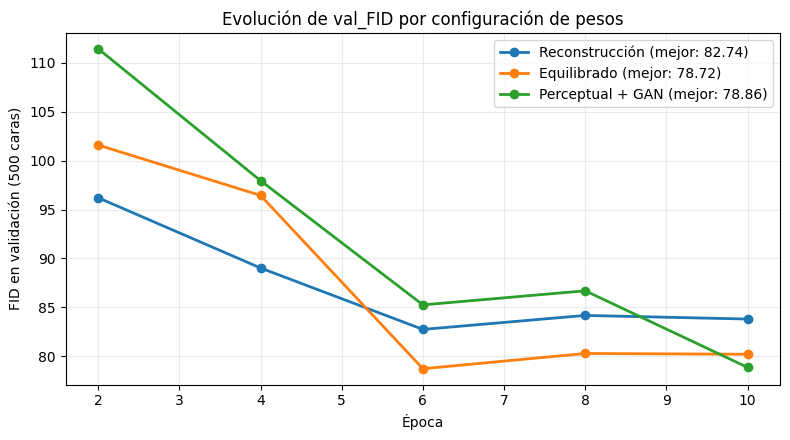

In [ ]:
# Fase 1
if TRAIN_MODEL:
    val_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    ablation_results = []

    for cfg in ABLATION_CONFIGS:
        print(
            f"\nEntrenando configuración '{cfg['name']}' "
            f"(gan={cfg['lambda_gan']}, l1={cfg['lambda_l1']}, perc={cfg['lambda_perc']}, {ABLATION_EPOCHS} epochs)",
            flush=True,
        )
        reset_seeds(SEED)
        train_ds_cfg = (
            tf.data.Dataset.from_tensor_slices((x_train_u8, y_train_u8))
            .shuffle(buffer_size=len(x_train_u8), seed=SEED, reshuffle_each_iteration=True)
            .map(_prepare_train_sample, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(BATCH_SIZE, drop_remainder=False)
            .prefetch(tf.data.AUTOTUNE)
        )
        gen_cfg = build_generator(NUM_CLASSES)
        disc_cfg = build_discriminator(NUM_CLASSES)
        g_opt_cfg, d_opt_cfg = make_optimizers(ABLATION_EPOCHS)

        p2p_cfg = Pix2Pix(
            gen_cfg,
            disc_cfg,
            lam_gan=cfg["lambda_gan"],
            lam_l1=cfg["lambda_l1"],
            lam_perc=cfg["lambda_perc"],
        )
        p2p_cfg.compile(g_optimizer=g_opt_cfg, d_optimizer=d_opt_cfg)

        cb_cfg = ValFIDAndTrackerCallback(
            x_val[:VAL_FID_SAMPLES],
            real_val_fid_feats,
            total_epochs=ABLATION_EPOCHS,
            every=VAL_FID_EVERY,
            capture_snapshots=False,
        )
        hist_cfg = p2p_cfg.fit(train_ds_cfg, validation_data=val_ds, epochs=ABLATION_EPOCHS, callbacks=[cb_cfg], verbose=1).history

        frac_start = compute_loss_fractions(
            float(hist_cfg["g_gan"][0]),
            float(hist_cfg["g_l1"][0]),
            float(hist_cfg["g_perc"][0]),
            cfg["lambda_gan"],
            cfg["lambda_l1"],
            cfg["lambda_perc"],
        )
        frac_end = compute_loss_fractions(
            float(hist_cfg["g_gan"][-1]),
            float(hist_cfg["g_l1"][-1]),
            float(hist_cfg["g_perc"][-1]),
            cfg["lambda_gan"],
            cfg["lambda_l1"],
            cfg["lambda_perc"],
        )
        best_idx = cb_cfg.best_epoch - 1
        ablation_results.append({
            "name": cfg["name"],
            "lambda_gan": cfg["lambda_gan"],
            "lambda_l1": cfg["lambda_l1"],
            "lambda_perc": cfg["lambda_perc"],
            "epochs": ABLATION_EPOCHS,
            "val_fid_epochs": cb_cfg.val_fid_epochs,
            "val_fid_scores": [round(float(v), 2) for v in cb_cfg.val_fid_scores],
            "best_val_fid": round(float(cb_cfg.best_fid), 2),
            "best_val_fid_epoch": int(cb_cfg.best_epoch),
            "val_g_l1_loss": [round(float(v), 4) for v in hist_cfg["val_g_l1"]],
            "val_one_minus_ssim": [round(float(v), 4) for v in hist_cfg["val_one_minus_ssim"]],
            "val_l1_at_best_fid": round(float(hist_cfg["val_g_l1"][best_idx]), 4),
            "val_one_minus_ssim_at_best_fid": round(float(hist_cfg["val_one_minus_ssim"][best_idx]), 4),
            "loss_fractions_start": frac_start,
            "loss_fractions_end": frac_end,
            "avg_epoch_time_s": round(float(np.mean(cb_cfg.epoch_time_s)), 1),
        })
        del gen_cfg, disc_cfg, p2p_cfg, g_opt_cfg, d_opt_cfg

    ABLATION_PATH.write_text(json.dumps(ablation_results, indent=2, ensure_ascii=False))
    print(f"\nResumen de la comparativa guardado en {ABLATION_PATH.name}")
else:
    if not ABLATION_PATH.exists():
        raise FileNotFoundError(f"Falta {ABLATION_PATH} para cargar la comparativa con TRAIN_MODEL=False.")
    ablation_results = json.loads(ABLATION_PATH.read_text())
    print(f"Comparativa cargada desde {ABLATION_PATH.name} ({len(ablation_results)} configuraciones).")

winner_cfg = min(ablation_results, key=lambda r: r["best_val_fid"])
LAMBDA_GAN = float(winner_cfg["lambda_gan"])
LAMBDA_L1 = float(winner_cfg["lambda_l1"])
LAMBDA_PERC = float(winner_cfg["lambda_perc"])

ablation_df = pd.DataFrame([
    {
        "Configuración": r["name"],
        "λ_GAN": r["lambda_gan"],
        "λ_L1": r["lambda_l1"],
        "λ_VGG": r["lambda_perc"],
        "Mejor val_FID": f"{r['best_val_fid']:.2f} (ep {r['best_val_fid_epoch']})",
        "val_L1": f"{r['val_l1_at_best_fid']:.4f}",
        "val 1 - SSIM": f"{r['val_one_minus_ssim_at_best_fid']:.4f}",
        "% GAN / L1 / VGG (final)": (
            f"{r['loss_fractions_end']['gan_pct']:.1f}% / "
            f"{r['loss_fractions_end']['l1_pct']:.1f}% / "
            f"{r['loss_fractions_end']['perc_pct']:.1f}%"
        ),
    }
    for r in ablation_results
])
display(ablation_df)
print(
    f"Configuración ganadora: {winner_cfg['name']} "
    f"(gan={LAMBDA_GAN}, l1={LAMBDA_L1}, perc={LAMBDA_PERC}, mejor val_fid={winner_cfg['best_val_fid']:.2f})"
)

fig, ax = plt.subplots(figsize=(8, 4.5))
for r in ablation_results:
    label = f"{r['name']} (mejor: {r['best_val_fid']:.2f})"
    ax.plot(r["val_fid_epochs"], r["val_fid_scores"], marker="o", linewidth=2, label=label)
ax.set_title("Evolución de val_FID por configuración de pesos")
ax.set_xlabel("Época")
ax.set_ylabel("FID en validación (500 caras)")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

#### **Elección de la configuración para el entrenamiento final**

La comparativa de 10 epochs deja a **`Equilibrado`** y **`Perceptual + GAN`** prácticamente empatadas, y por eso para el entrenamiento definitivo de 30 epochs elegimos **`Perceptual + GAN`** (`λ_GAN = 3.0`, `λ_L1 = 20.0`, `λ_VGG = 0.08`), aunque la regla de mínimo `val_fid` habría seleccionado `Equilibrado`.

**1. La diferencia de FID es ruido.** El mejor `val_fid` de `Equilibrado` (78.72) y el de `Perceptual + GAN` (78.86) difieren en 0.14 puntos. El FID se calcula sobre solo 500 caras y con una única ejecución por configuración, así que diferencias tan mínimas no son distinguibles.

**2. Compararlas en la misma fase del entrenamiento es más justo.** `Equilibrado` consigue su mejor valor en la época 6, con la tasa de aprendizaje todavía alta, y después se estanca. `Perceptual + GAN` lo hace en la época 10, con el `CosineDecay` completado. 

| Configuración | Mejor `val_fid` (epoch) | `val_fid` en la época 10 |
|---|---|---|
| Reconstrucción (1.0 / 50.0 / 0.04) | 82.74 (6) | 83.80 |
| Equilibrado (2.5 / 30.0 / 0.05) | 78.72 (6) | 80.20 |
| **Perceptual + GAN (3.0 / 20.0 / 0.08)** | 78.86 (10) | **78.86** |

**3. `Perceptual + GAN` no parece haber saturado.** Su FID bajó de 86.69 a 78.86 entre las épocas 8 y 10, mientras que el de `Equilibrado` se mantuvo plano (80.28 -> 80.20) desde la época 6. Esto sugiere más margen de mejora con 30 epochs.

In [ ]:
# Fase 2
if TRAIN_MODEL:
    
    winner_cfg = next(r for r in ablation_results if r["name"] == "Perceptual + GAN")
    LAMBDA_GAN, LAMBDA_L1, LAMBDA_PERC = winner_cfg["lambda_gan"], winner_cfg["lambda_l1"], winner_cfg["lambda_perc"]

    reset_seeds(SEED)
    train_ds = (
        tf.data.Dataset.from_tensor_slices((x_train_u8, y_train_u8))
        .shuffle(buffer_size=len(x_train_u8), seed=SEED, reshuffle_each_iteration=True)
        .map(_prepare_train_sample, num_parallel_calls=tf.data.AUTOTUNE)
        .batch(BATCH_SIZE, drop_remainder=False)
        .prefetch(tf.data.AUTOTUNE)
    )
    val_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    generator = build_generator(NUM_CLASSES)
    discriminator = build_discriminator(NUM_CLASSES)
    generator_optimizer, discriminator_optimizer = make_optimizers(EPOCHS)

    pix2pix = Pix2Pix(
        generator, discriminator, lam_gan=LAMBDA_GAN, lam_l1=LAMBDA_L1, lam_perc=LAMBDA_PERC
    )
    pix2pix.compile(g_optimizer=generator_optimizer, d_optimizer=discriminator_optimizer)

    fid_cb = ValFIDAndTrackerCallback(
        x_val[:VAL_FID_SAMPLES],
        real_val_fid_feats,
        total_epochs=EPOCHS,
        every=VAL_FID_EVERY,
        capture_snapshots=True,
    )
    print(
        f"Entrenamiento final ({EPOCHS} épocas) con '{winner_cfg['name']}' "
        f"(gan={LAMBDA_GAN}, l1={LAMBDA_L1}, perc={LAMBDA_PERC})...",
        flush=True,
    )
    fit_hist = pix2pix.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=[fid_cb], verbose=1)

    raw = fit_hist.history
    key_map = {
        "g_tot": "g_total_loss",
        "g_gan": "g_gan_loss",
        "g_l1": "g_l1_loss",
        "g_perc": "g_perc_loss",
        "d": "d_loss",
        "val_g_tot": "val_g_total_loss",
        "val_g_gan": "val_g_gan_loss",
        "val_g_l1": "val_g_l1_loss",
        "val_g_perc": "val_g_perc_loss",
        "val_d": "val_d_loss",
        "val_recon": "val_recon",
        "val_one_minus_ssim": "val_one_minus_ssim",
    }
    history = {dst: [float(v) for v in raw[src]] for src, dst in key_map.items() if src in raw}
    history["selected_config"] = {
        "name": winner_cfg["name"],
        "lambda_gan": LAMBDA_GAN,
        "lambda_l1": LAMBDA_L1,
        "lambda_perc": LAMBDA_PERC,
    }
    history["epoch_time_s"] = fid_cb.epoch_time_s
    history["val_fid_epochs"] = fid_cb.val_fid_epochs
    history["val_fid_scores"] = fid_cb.val_fid_scores
    history["best_val_fid_epoch"] = fid_cb.best_epoch
    history["best_val_fid"] = float(fid_cb.best_fid)

    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
    generator.save(GENERATOR_PATH)
    discriminator.save(DISCRIMINATOR_PATH)
    HISTORY_PATH.write_text(json.dumps(history, indent=2))
    np.savez_compressed(
        VAL_EVOLUTION_PATH,
        epochs=np.array(fid_cb.snap_epochs, dtype=np.int32),
        preds=np.array(fid_cb.snap_preds, dtype=np.float32),
        probe_indices=PROBE_INDICES,
    )
    print(f"Checkpoints guardados (G y D) en {CHECKPOINT_DIR.resolve()}")
else:
    required = [GENERATOR_PATH, DISCRIMINATOR_PATH, HISTORY_PATH, MASK_CLASSES_PATH]
    missing = [str(p) for p in required if not p.exists()]
    if missing:
        raise FileNotFoundError("Faltan checkpoints para TRAIN_MODEL=False: " + ", ".join(missing))
    generator = keras.models.load_model(GENERATOR_PATH, compile=False)
    discriminator = keras.models.load_model(DISCRIMINATOR_PATH, compile=False)
    history = json.loads(HISTORY_PATH.read_text())
    sel = history.get("selected_config", {})
    if sel:
        LAMBDA_GAN = float(sel["lambda_gan"])
        LAMBDA_L1 = float(sel["lambda_l1"])
        LAMBDA_PERC = float(sel["lambda_perc"])
    print(
        f"Checkpoints cargados ({len(history['g_total_loss'])} épocas, "
        f"mejor val_fid={history.get('best_val_fid', float('nan')):.2f} en época {history.get('best_val_fid_epoch', 'N/D')})."
    )

print_loss_fractions(history, 0, "inicio", LAMBDA_GAN, LAMBDA_L1, LAMBDA_PERC)
print_loss_fractions(history, len(history["g_total_loss"]) - 1, "final", LAMBDA_GAN, LAMBDA_L1, LAMBDA_PERC)

Entrenamiento final (30 épocas) con 'Perceptual + GAN' (gan=3.0, l1=20.0, perc=0.08)...
Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 226s 585ms/step - d: 0.2295 - g_gan: 0.5686 - g_l1: 0.3953 - g_perc: 256.7741 - g_tot: 30.1536 - val_d: 0.0822 - val_g_gan: 0.6847 - val_g_l1: 0.3918 - val_g_perc: 246.5218 - val_g_tot: 29.6125 - val_one_minus_ssim: 0.5714 - val_recon: 27.5583
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 233s 620ms/step - d: 0.0915 - g_gan: 0.6518 - g_l1: 0.3932 - g_perc: 242.0306 - g_tot: 29.1816 - val_d: 0.0879 - val_g_gan: 0.7610 - val_g_l1: 0.4008 - val_g_perc: 249.9925 - val_g_tot: 30.2977 - val_one_minus_ssim: 0.5638 - val_recon: 28.0146 - val_fid: 110.4823
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 230s 614ms/step - d: 0.0875 - g_gan: 0.6969 - g_l1: 0.3966 - g_perc: 244.1873 - g_tot: 29.5578 - val_d: 0.0580 - val_g_gan: 0.7435 - val_g_l1: 0.3945 - val_g_perc: 251.0286 - val_g_tot: 30.2028 - val_one_minus_ssim: 0.5665 - val_recon: 27.9722
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 

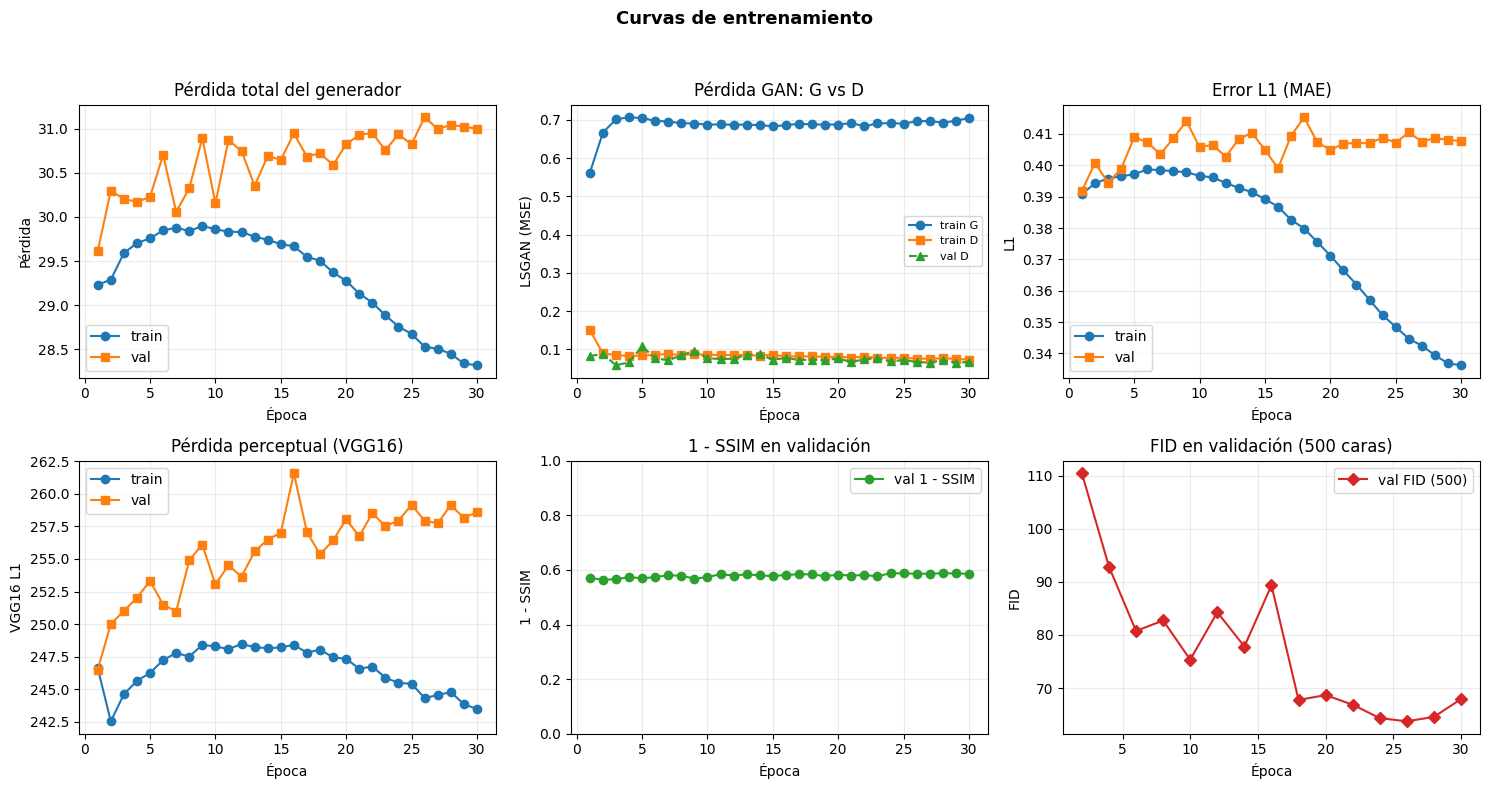

Resumen validación: mejor val_fid en época 26 (63.73) | mejor val_l1 en época 1 (0.3918) | mejor val_1-ssim en época 2 (0.5638) | tiempo medio/época: 231.6s


In [34]:
epochs_axis = np.arange(1, len(history["g_total_loss"]) + 1)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

axes[0, 0].plot(epochs_axis, history["g_total_loss"], marker="o", label="train")
axes[0, 0].plot(epochs_axis, history["val_g_total_loss"], marker="s", label="val")
axes[0, 0].set_title("Pérdida total del generador")
axes[0, 0].set_xlabel("Época")
axes[0, 0].set_ylabel("Pérdida")
axes[0, 0].grid(alpha=0.25)
axes[0, 0].legend()

axes[0, 1].plot(epochs_axis, history["g_gan_loss"], marker="o", label="train G")
axes[0, 1].plot(epochs_axis, history["d_loss"], marker="s", label="train D")
axes[0, 1].plot(epochs_axis, history["val_d_loss"], marker="^", linestyle="--", label="val D")
axes[0, 1].set_title("Pérdida GAN: G vs D")
axes[0, 1].set_xlabel("Época")
axes[0, 1].set_ylabel("LSGAN (MSE)")
axes[0, 1].grid(alpha=0.25)
axes[0, 1].legend(fontsize=8)

axes[0, 2].plot(epochs_axis, history["g_l1_loss"], marker="o", label="train")
axes[0, 2].plot(epochs_axis, history["val_g_l1_loss"], marker="s", label="val")
axes[0, 2].set_title("Error L1 (MAE)")
axes[0, 2].set_xlabel("Época")
axes[0, 2].set_ylabel("L1")
axes[0, 2].grid(alpha=0.25)
axes[0, 2].legend()

axes[1, 0].plot(epochs_axis, history["g_perc_loss"], marker="o", label="train")
axes[1, 0].plot(epochs_axis, history["val_g_perc_loss"], marker="s", label="val")
axes[1, 0].set_title("Pérdida perceptual (VGG16)")
axes[1, 0].set_xlabel("Época")
axes[1, 0].set_ylabel("VGG16 L1")
axes[1, 0].grid(alpha=0.25)
axes[1, 0].legend()

axes[1, 1].plot(epochs_axis, history["val_one_minus_ssim"], marker="o", color="tab:green", label="val 1 - SSIM")
axes[1, 1].set_title("1 - SSIM en validación")
axes[1, 1].set_xlabel("Época")
axes[1, 1].set_ylabel("1 - SSIM")
axes[1, 1].set_ylim(0.0, 1.0)
axes[1, 1].grid(alpha=0.25)
axes[1, 1].legend()

if history.get("val_fid_epochs"):
    axes[1, 2].plot(history["val_fid_epochs"], history["val_fid_scores"], marker="D", color="tab:red", label="val FID (500)")
    axes[1, 2].set_title("FID en validación (500 caras)")
    axes[1, 2].set_xlabel("Época")
    axes[1, 2].set_ylabel("FID")
    axes[1, 2].grid(alpha=0.25)
    axes[1, 2].legend()
else:
    axes[1, 2].axis("off")

plt.suptitle("Curvas de entrenamiento", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

best_l1_ep = int(np.argmin(history["val_g_l1_loss"])) + 1
best_1ms_ep = int(np.argmin(history["val_one_minus_ssim"])) + 1
print(
    f"Resumen validación: mejor val_fid en época {history.get('best_val_fid_epoch', 'N/D')} "
    f"({history.get('best_val_fid', float('nan')):.2f}) | "
    f"mejor val_l1 en época {best_l1_ep} ({min(history['val_g_l1_loss']):.4f}) | "
    f"mejor val_1-ssim en época {best_1ms_ep} ({min(history['val_one_minus_ssim']):.4f}) | "
    f"tiempo medio/época: {np.mean(history['epoch_time_s']):.1f}s"
)

#### **Interpretación de las curvas de entrenamiento**

A primera vista, la separación entre las curvas de entrenamiento (`train`) y validación (`val`) en la pérdida total, `L1` y `VGG16` podría parecer un caso *overfitting* o un entrenamiento fallido. Sin embargo, en una GAN condicional entrenada a partir de máscaras binarias esta lectura puede engañar: hay que interpretar todas las gráficas en conjunto.

* **Pérdida total, Error L1 (MAE) y VGG16 (arriba izquierda, arriba derecha y abajo izquierda):** a partir de la época 12–15 las curvas de `train` descienden de forma clara, mientras que en `val` suben ligeramente o se estancan (nota: el `L1` de estas curvas se calcula en escala `[-1, 1]`, por eso ronda `~0.41` frente a `~0.205` en la tabla final desnormalizada a `[0, 1]`). Esto ocurre por dos motivos:
  1. **Ambigüedad de la máscara:** una máscara indica la forma y posición de cada rasgo, pero no el color del pelo, el tono de piel, la iluminación ni el fondo. En las primeras epochs el generador dibuja caras borrosas con colores promedio que minimizan el error píxel a píxel en validación (algo como lo que haría el MAE o MSE), pero resultan poco realistas. Cuando avanza el entrenamiento y empieza a sintetizar texturas y colores más nítidas, cualquier diferencia de color o iluminación respecto a la foto real penaliza los errores, aunque la cara generada sea mucho más creíble.
  2. **Posible sobreajuste parcial en `train`:** la caída continua de `train L1` en la segunda mitad del entrenamiento apunta a un posible sobreajuste parcial a colores y fondos de entrenamiento a medida que baja la tasa de aprendizaje, con la salvedad de que `train` incluye `Dropout` y *data augmentation* (mientras `val` se evalúa sin ellos).

* **Pérdida GAN: G vs D (arriba centro):** tras la primera época de ajuste, ambas redes se estabilizan por completo (`train G ≈ 0.69`; `train D` y `val D` prácticamente superpuestas en `~0.07–0.08`). Que `train D` y `val D` sigan la misma trayectoria confirma que el discriminador no sobreajusta ni colapsa. Esto nos dice dos cosas: la combinación de `LSGAN` y `SpectralNormalization` mantiene un entrenamiento estable durante las 30 épocas, aunque refleja la complejidad de ajustar una GAN y encontrar una estabilidad sana entre G y D para que ambos aprendan.

* **1 - SSIM en validación (abajo centro):** se mantiene casi plana (`~0.56` a `~0.59`). Al tratarse también de una métrica frente a la foto real exacta, tiene el mismo efecto que `L1`: no premia el aumento de nitidez si los tonos o la iluminación no coinciden con el original. Estos razonamientos de incremento de nitidez no son una hipótesis, sino que se confirman al observar la evolución de `val_fid`. En la siguiente celda veremos también la comprobación visual.

* **FID en validación sobre 500 caras (abajo derecha):** es el indicador más fiable de calidad visual porque compara distribuciones de caras en lugar de píxeles. Baja de forma progresiva desde `110.48` (época 2) hasta `75.35` (época 10), da un salto claro en la época 18 (`67.76`) y alcanza su mínimo en la **época 26 (`63.73`)**, tras lo cual empieza a saturar y repunta. Al calcularse sobre solo 500 caras, este `val_fid` tiene sesgo al alza por tamaño muestral y no es comparable directamente con el FID de `test` sobre 3.000 muestras (`48.15`), aunque sirve para comparar épocas entre sí.

En conjunto, las curvas confirman un entrenamiento coherente con la tarea: el ligero empeoramiento de `val L1`, `val VGG16` y `1 - SSIM` no señala un fallo del modelo, sino el paso de caras suavizadas a caras nítidas y realistas. Al mismo tiempo, el posible sobreajuste parcial en las últimas épocas justifica seleccionar el modelo por mínimo `val_fid` (los resultados serían mucho peores si solo eligiésemos el modelo con menor pérdida en lugar de aprender a interpretar el resultado).

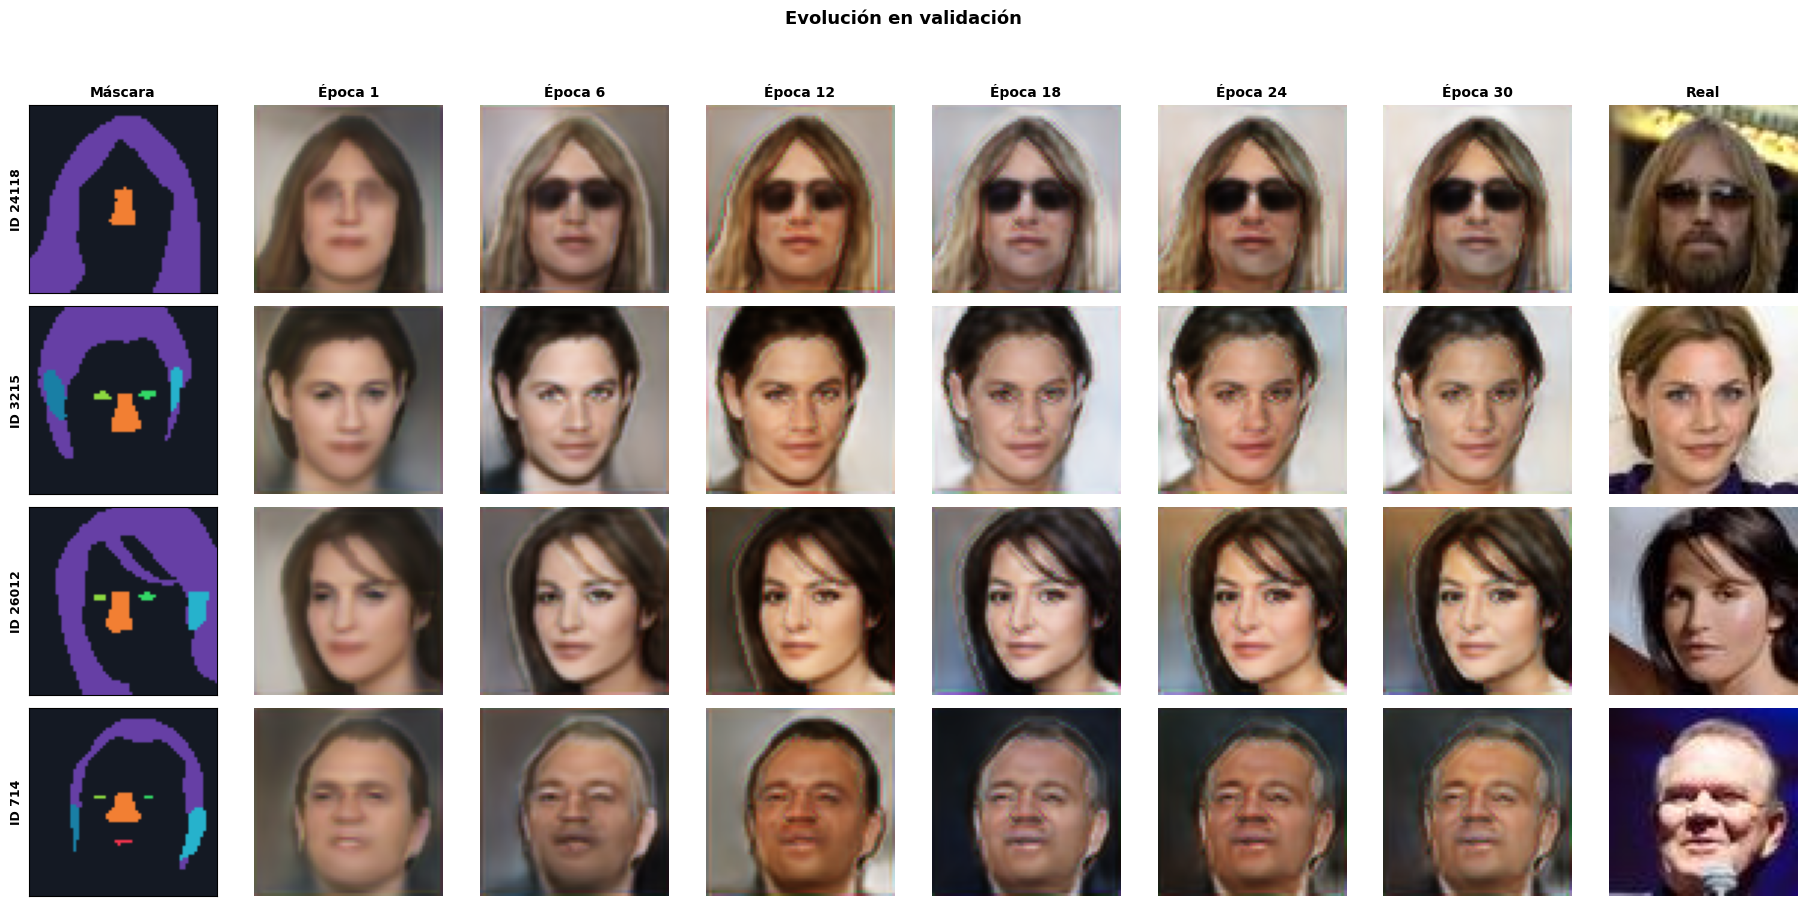

In [35]:
if VAL_EVOLUTION_PATH.exists():
    evo_data = np.load(VAL_EVOLUTION_PATH)
    snap_epochs = evo_data["epochs"]
    snap_preds = evo_data["preds"]
else:
    snap_epochs = np.array([len(history["g_total_loss"])])
    snap_preds = generate(probe_masks)[None, ...]

n_rows = len(PROBE_INDICES)
n_cols = len(snap_epochs) + 2
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.3 * n_cols, 2.3 * n_rows))

for r_idx in range(n_rows):
    axes[r_idx, 0].imshow(colorize_mask(probe_masks[r_idx]))
    axes[r_idx, 0].set_title("Máscara" if r_idx == 0 else "", fontsize=10, fontweight="bold")
    axes[r_idx, 0].set_ylabel(f"ID {ids_val[PROBE_INDICES[r_idx]]}", fontsize=9, fontweight="bold")
    axes[r_idx, 0].set_xticks([]); axes[r_idx, 0].set_yticks([])

    for c_idx, ep_num in enumerate(snap_epochs):
        axes[r_idx, c_idx + 1].imshow(denormalize_image(snap_preds[c_idx, r_idx]))
        axes[r_idx, c_idx + 1].set_title(f"Época {ep_num}" if r_idx == 0 else "", fontsize=10, fontweight="bold")
        axes[r_idx, c_idx + 1].axis("off")

    axes[r_idx, -1].imshow(denormalize_image(probe_reals[r_idx]))
    axes[r_idx, -1].set_title("Real" if r_idx == 0 else "", fontsize=10, fontweight="bold")
    axes[r_idx, -1].axis("off")

plt.suptitle("Evolución en validación", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

---

## **6. Evaluación cualitativa y mezcla de caras (`mix_faces` y `mix_grid`)**

1. **Cuadrícula en `test`:** comparamos la máscara de entrada, la cara generada $G(x)$, la cara real $y$ y el mapa de error absoluto $|y - G(x)|$ sobre ejemplos de `test` no vistos durante el entrenamiento.

2. **Mezcla de caras:**
   - `sample_pairs(n_pairs, attrs_options, split, seed, contrast)` para muestreo reproducible: con `contrast=True` busca cambios visibles (sombrero vs sin sombrero y pelo corto vs largo con diferencia mínima de píxeles); con `contrast=False` muestrea pares y atributos al azar para las `3.000` caras nuevas.
   - `mix_faces(idx_a, idx_b, attrs_from_b, split="test", show=True, idx_c=None, attrs_from_c=None)` genera una cara combinando 2 o 3 personas a partir de sus índices.
   - `mix_grid(pairs=None, n_pairs=5, ..., pair_seed=...)` dibuja 5 combinaciones entre 2 personas.

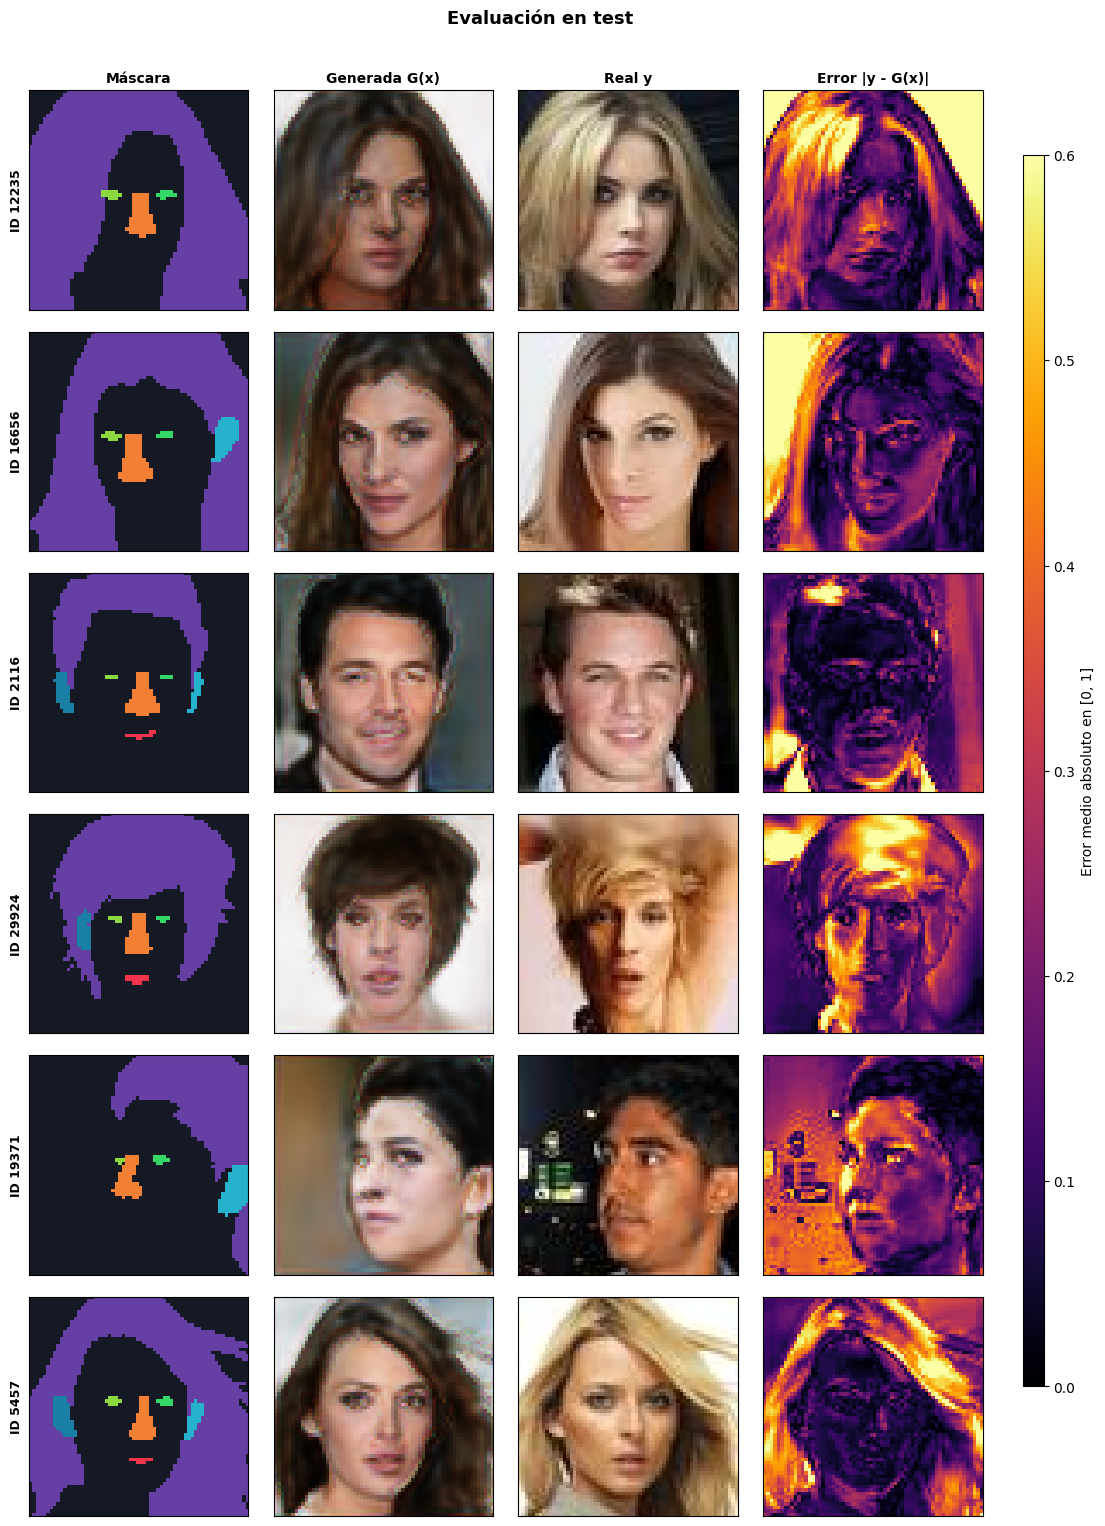

In [36]:
y_test_pred = generate(x_test)
qual_indices = np.random.default_rng(SEED).choice(len(x_test), size=6, replace=False)

fig, axes = plt.subplots(len(qual_indices), 4, figsize=(11.5, 2.7 * len(qual_indices)))
col_titles = ["Máscara", "Generada G(x)", "Real y", "Error |y - G(x)|"]
last_im = None

for row_idx, t_idx in enumerate(qual_indices):
    gen_rgb = denormalize_image(y_test_pred[t_idx])
    real_rgb = denormalize_image(y_test[t_idx])
    abs_err = np.mean(np.abs(real_rgb - gen_rgb), axis=-1)

    axes[row_idx, 0].imshow(colorize_mask(x_test[t_idx]))
    axes[row_idx, 1].imshow(gen_rgb)
    axes[row_idx, 2].imshow(real_rgb)
    last_im = axes[row_idx, 3].imshow(abs_err, cmap="inferno", vmin=0.0, vmax=0.6)
    axes[row_idx, 0].set_ylabel(f"ID {ids_test[t_idx]}", fontsize=9, fontweight="bold")
    for c_idx in range(4):
        if row_idx == 0:
            axes[row_idx, c_idx].set_title(col_titles[c_idx], fontsize=10, fontweight="bold")
        axes[row_idx, c_idx].set_xticks([]); axes[row_idx, c_idx].set_yticks([])

cbar_ax = fig.add_axes([0.92, 0.12, 0.018, 0.76])
fig.colorbar(last_im, cax=cbar_ax, label="Error medio absoluto en [0, 1]")
fig.suptitle("Evaluación en test", fontsize=13, fontweight="bold", y=0.97)
fig.subplots_adjust(left=0.05, right=0.89, top=0.92, bottom=0.04, hspace=0.10, wspace=0.06)
fig.savefig(CHECKPOINT_DIR / "gan_test_grid.png", dpi=140, bbox_inches="tight")
plt.show()

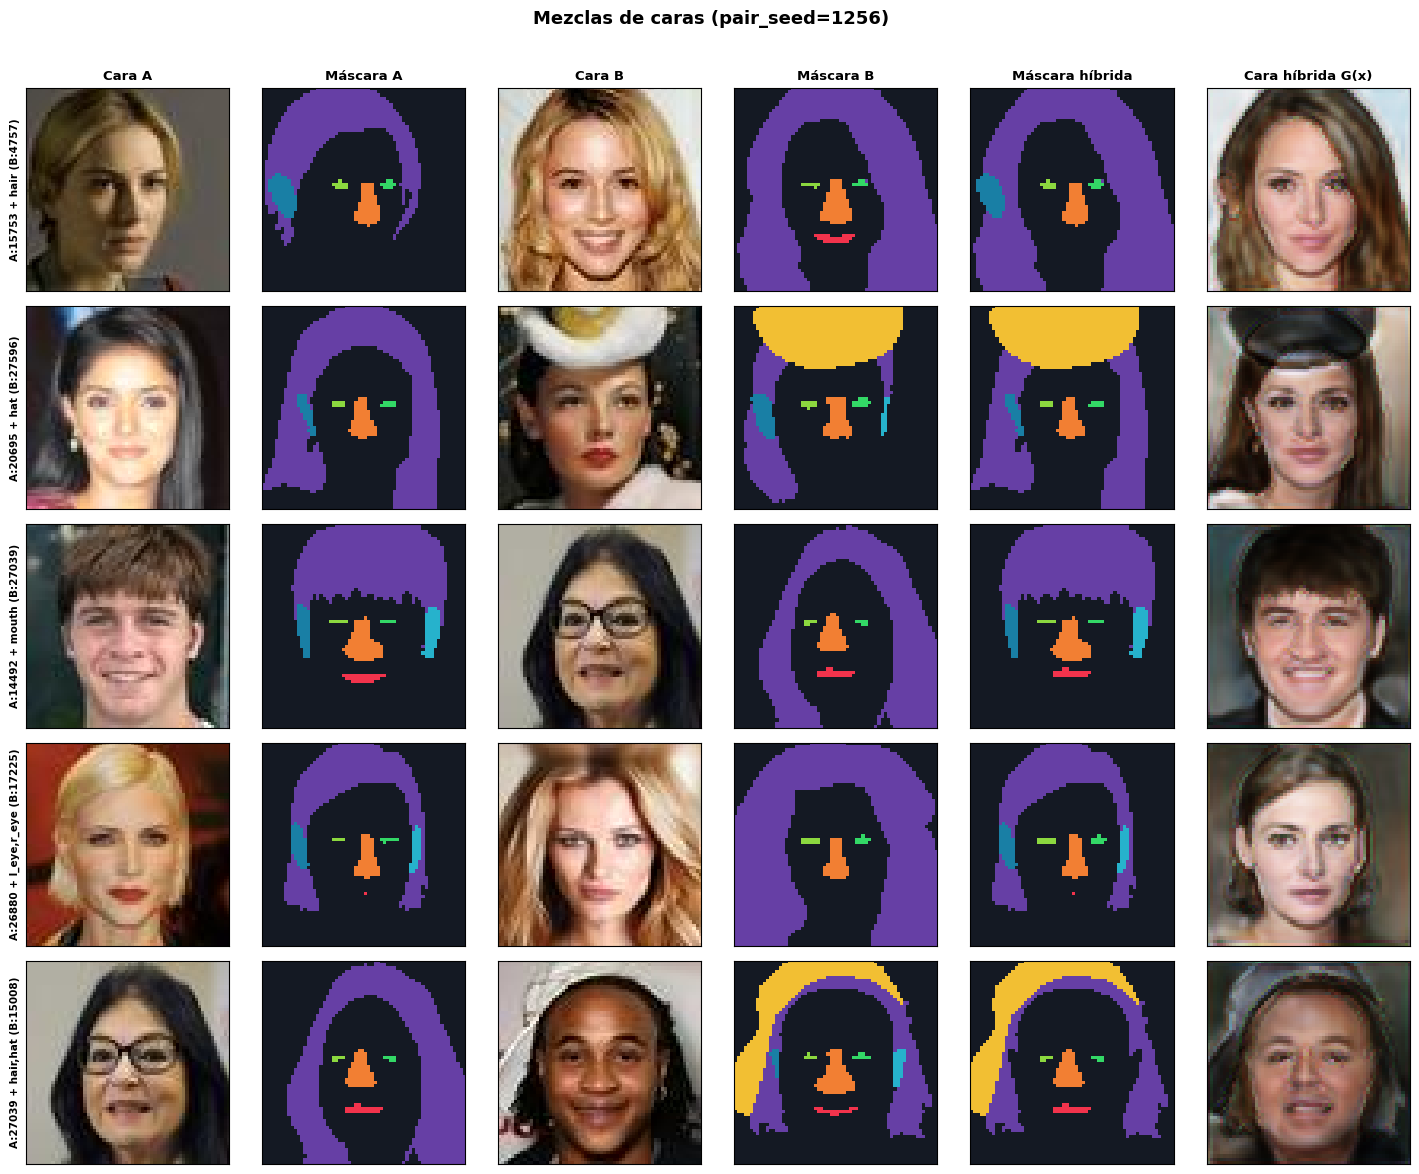

In [ ]:
SPLIT_STORE = {
    "test": (x_test, y_test, ids_test),
    "val": (x_val, y_val, ids_val),
}

DEFAULT_ATTRS_OPTIONS = [
    ["hair"],
    ["hat"],
    ["mouth"],
    ["l_eye", "r_eye"],
    ["hair", "hat"],
    ["l_ear", "r_ear"],
    ["nose"],
]


def _resolve_split_index(idx_or_id, ids_arr: np.ndarray) -> int:
    if isinstance(idx_or_id, str):
        matches = np.where(ids_arr == idx_or_id)[0]
        if len(matches) == 0:
            raise ValueError(f"ID '{idx_or_id}' no encontrado en el split.")
        return int(matches[0])
    idx = int(idx_or_id)
    if 0 <= idx < len(ids_arr):
        return idx
    matches = np.where(ids_arr == str(idx))[0]
    if len(matches) > 0:
        return int(matches[0])
    raise IndexError(f"Índice o ID {idx_or_id} fuera de rango para split de tamaño {len(ids_arr)}.")


def hybridize_masks(
    mask_a: np.ndarray,
    mask_b: np.ndarray,
    attrs_from_b: list[str],
    mask_classes: list[str] = MASK_CLASSES,
) -> np.ndarray:
    """Combina mask_a reemplazando los canales indicados con los de mask_b."""
    hybrid = mask_a.copy()
    for attr in attrs_from_b:
        if attr in mask_classes:
            c_idx = mask_classes.index(attr)
            hybrid[:, :, c_idx] = mask_b[:, :, c_idx]
    return hybrid


def sample_pairs(
    n_pairs: int,
    attrs_options: list[list[str]] = DEFAULT_ATTRS_OPTIONS,
    split: str = "test",
    seed: int = SEED,
    contrast: bool = True,
) -> list[tuple[int, int, list[str]]]:
    
    x_s = SPLIT_STORE[split][0]
    n_total, rng = len(x_s), np.random.default_rng(seed)
    options = [opt for opt in ([a for a in o if a in MASK_CLASSES] for o in attrs_options) if opt]
    if not contrast:
        return [
            (ia, (ia + 1 + int(rng.integers(n_total - 1))) % n_total, options[int(rng.integers(len(options)))])
            for ia in rng.integers(n_total, size=n_pairs).tolist()
        ]
    areas = {cls: x_s[:, :, :, MASK_CLASSES.index(cls)].sum(axis=(1, 2)) for cls in MASK_CLASSES}
    has_hat = areas["hat"] > 30 if "hat" in areas else np.zeros(n_total, dtype=bool)
    hair_low, hair_high = np.percentile(areas["hair"], [35, 65]) if "hair" in areas else (0, 0)
    pairs = []
    for idx in range(n_pairs):
        attrs = options[idx % len(options)] if idx < len(options) else options[int(rng.integers(len(options)))]
        min_diff = 120 if ("hair" in attrs or "hat" in attrs) else 10
        if "hat" in attrs and "hat" in areas:
            pool_a, pool_b = np.where(~has_hat)[0], np.where(has_hat)[0]
        elif "hair" in attrs and "hair" in areas:
            short_p = np.where((~has_hat) & (areas["hair"] <= hair_low))[0]
            long_p = np.where((~has_hat) & (areas["hair"] >= hair_high))[0]
            pool_a, pool_b = (short_p, long_p) if rng.random() < 0.5 else (long_p, short_p)
        else:
            present_b = np.logical_and.reduce([areas[a] > 4 for a in attrs])
            pool_a, pool_b = np.where(~has_hat)[0], np.where((~has_hat) & present_b)[0]
        if len(pool_a) == 0 or len(pool_b) == 0:
            pool_a = pool_b = np.arange(n_total)
        ia, ib = int(rng.choice(pool_a)), int(rng.choice(pool_b))
        for _ in range(100):
            if ia != ib and np.abs(hybridize_masks(x_s[ia], x_s[ib], attrs) - x_s[ia]).sum() >= min_diff:
                break
            ia, ib = int(rng.choice(pool_a)), int(rng.choice(pool_b))
        pairs.append((ia, ib, attrs))
    return pairs


def mix_faces(
    idx_a,
    idx_b,
    attrs_from_b: list[str] | None = None,
    split: str = "test",
    show: bool = True,
    idx_c=None,
    attrs_from_c: list[str] | None = None,
):
   
    x_s, y_s, ids_s = SPLIT_STORE[split]
    ia = _resolve_split_index(idx_a, ids_s)
    ib = _resolve_split_index(idx_b, ids_s)
    attrs_b = [a for a in (attrs_from_b or []) if a in MASK_CLASSES]
    attrs_c = [a for a in (attrs_from_c or []) if a in MASK_CLASSES] if idx_c is not None else []

    hybrid_mask = hybridize_masks(x_s[ia], x_s[ib], attrs_b)
    if idx_c is not None:
        ic = _resolve_split_index(idx_c, ids_s)
        hybrid_mask = hybridize_masks(hybrid_mask, x_s[ic], attrs_c)
    gen_face = generate(hybrid_mask)

    if show:
        panels = [
            (denormalize_image(y_s[ia]), f"Cara A ({ids_s[ia]})"),
            (colorize_mask(x_s[ia]), "Máscara A"),
            (denormalize_image(y_s[ib]), f"Cara B ({ids_s[ib]})"),
            (colorize_mask(x_s[ib]), "Máscara B"),
        ]
        if idx_c is not None:
            panels += [
                (denormalize_image(y_s[ic]), f"Cara C ({ids_s[ic]})"),
                (colorize_mask(x_s[ic]), "Máscara C"),
            ]
        panels += [
            (colorize_mask(hybrid_mask), "Máscara híbrida"),
            (denormalize_image(gen_face), "Cara híbrida G(x)"),
        ]
        nrows, ncols, figsize = (1, 6, (14.4, 2.7)) if idx_c is None else (2, 4, (11.2, 6.0))
        fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
        for ax, (img_p, title) in zip(np.ravel(axes), panels):
            ax.imshow(img_p)
            ax.set_title(title, fontsize=9.5, fontweight="bold")
            ax.axis("off")
        plt.tight_layout()
        plt.show()

    return hybrid_mask, gen_face


def mix_grid(
    pairs: list[tuple[int, int, list[str]]] | None = None,
    n_pairs: int = 5,
    attrs_options: list[list[str]] = DEFAULT_ATTRS_OPTIONS,
    pair_seed: int = SEED + 42,
    split: str = "test",
    contrast: bool = True,
    save_path: Path | None = None,
):
   
    x_s, y_s, ids_s = SPLIT_STORE[split]
    if pairs is None:
        pairs = sample_pairs(n_pairs=n_pairs, attrs_options=attrs_options, split=split, seed=pair_seed, contrast=contrast)

    hyb_masks = np.stack([
        hybridize_masks(x_s[_resolve_split_index(ia, ids_s)], x_s[_resolve_split_index(ib, ids_s)], attrs)
        for ia, ib, attrs in pairs
    ], axis=0)
    hyb_faces = generate(hyb_masks)

    fig, axes = plt.subplots(len(pairs), 6, figsize=(14.5, 2.35 * len(pairs)), squeeze=False)
    headers = ["Cara A", "Máscara A", "Cara B", "Máscara B", "Máscara híbrida", "Cara híbrida G(x)"]
    for row_idx, (ia_raw, ib_raw, attrs) in enumerate(pairs):
        ia = _resolve_split_index(ia_raw, ids_s)
        ib = _resolve_split_index(ib_raw, ids_s)
        panels = [
            denormalize_image(y_s[ia]),
            colorize_mask(x_s[ia]),
            denormalize_image(y_s[ib]),
            colorize_mask(x_s[ib]),
            colorize_mask(hyb_masks[row_idx]),
            denormalize_image(hyb_faces[row_idx]),
        ]
        for col_idx, img_p in enumerate(panels):
            axes[row_idx, col_idx].imshow(img_p)
            if row_idx == 0:
                axes[row_idx, col_idx].set_title(headers[col_idx], fontsize=9.5, fontweight="bold")
            if col_idx == 0:
                axes[row_idx, col_idx].set_ylabel(f"A:{ids_s[ia]} + {','.join(attrs)} (B:{ids_s[ib]})", fontsize=7.5, fontweight="bold")
            axes[row_idx, col_idx].set_xticks([]); axes[row_idx, col_idx].set_yticks([])

    plt.suptitle(f"Mezclas de caras (pair_seed={pair_seed})", fontsize=13, fontweight="bold", y=0.995)
    plt.tight_layout(rect=[0, 0, 1, 0.985])
    if save_path is not None:
        fig.savefig(save_path, dpi=130, bbox_inches="tight")
    plt.show()
    return pairs


sampled_pairs = mix_grid(n_pairs=5, pair_seed=SEED + 22, save_path=CHECKPOINT_DIR / "gan_mix_grid.png")

In [ ]:
DEFAULT_ATTRS_OPTIONS = [
    ["hair"],
    ["hat"],
    ["mouth"],
    ["l_eye", "r_eye"],
    ["hair", "hat"],
    ["l_ear", "r_ear"],
    ["nose"],
]

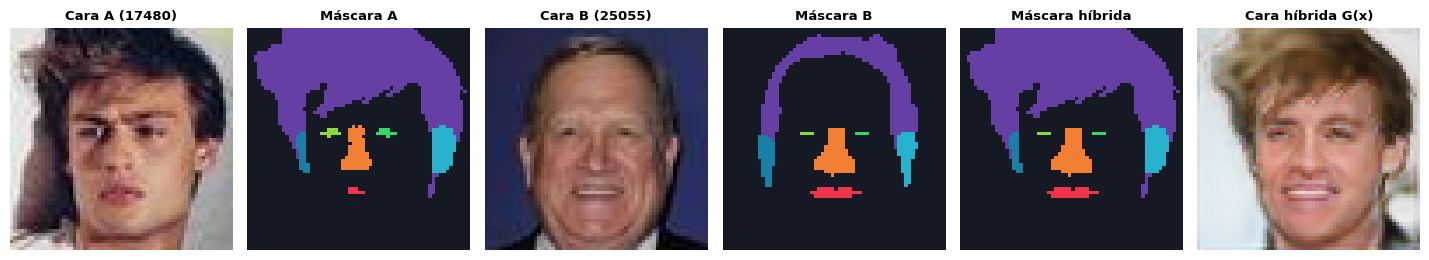

(array([[[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.]],
 
        [[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.]],
 
        [[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.]],
 
        ...,
 
        [[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],


In [ ]:
# Mezclar 2 personas (ojos, boca y nariz de B sobre A):
    
mix_faces(
    idx_a=20,
    idx_b=30,
    attrs_from_b=["l_eye", "r_eye", "nose", "mouth"],
)

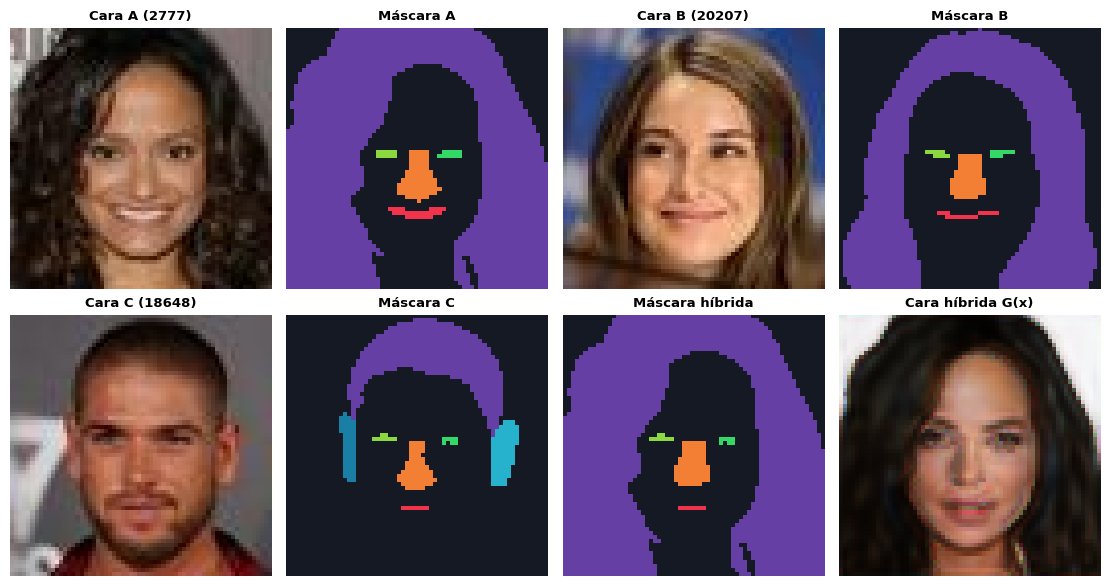

(array([[[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.]],
 
        [[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.]],
 
        [[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.]],
 
        ...,
 
        [[1., 0., 0., ..., 0., 0., 0.],
         [1., 0., 0., ..., 0., 0., 0.],
         [1., 0., 0., ..., 0., 0., 0.],
         ...,
         [1., 0., 0., ..., 0., 0., 0.],
         [1., 0., 0., ..., 0., 0., 0.],


In [ ]:
# Mezclar 3 personas (nariz de B + ojos y boca de C sobre A):

mix_faces(
    idx_a=10,
    idx_b=40,
    attrs_from_b=["nose"],
    idx_c=42,
    attrs_from_c=["l_eye", "r_eye", "mouth"],
)

Caras con gorro en test: 129
Primeros índices: [9, 36, 90, 94, 112, 118, 129, 138, 163, 168, 181, 182, 212, 257, 284, 314, 356, 380, 391, 399]


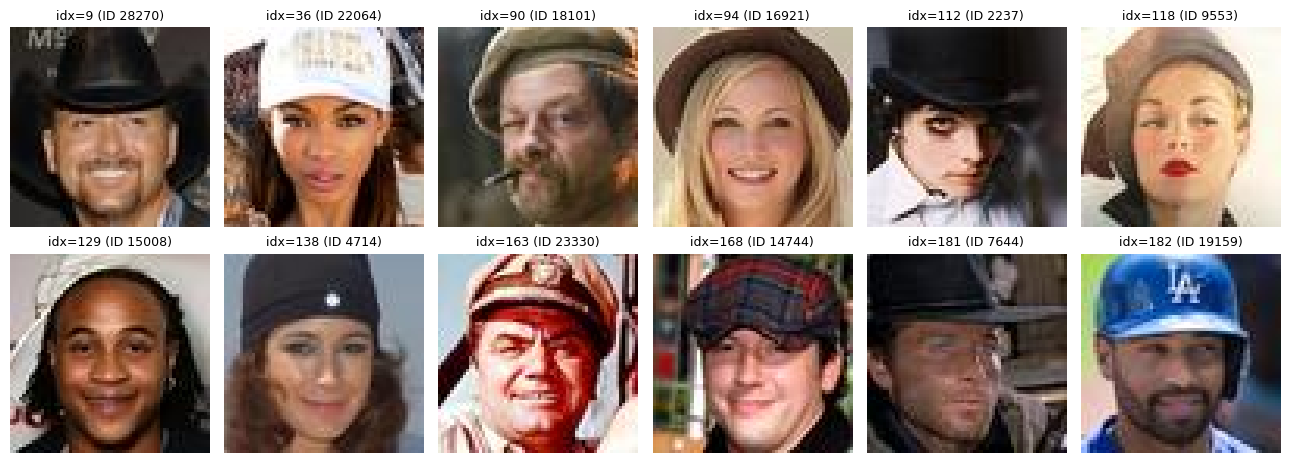

In [ ]:
hat_idx = MASK_CLASSES.index("hat")
hat_indices = np.where(x_test[:, :, :, hat_idx].sum(axis=(1, 2)) > 30)[0]

print(f"Caras con gorro en test: {len(hat_indices)}")
print("Primeros índices:", hat_indices[:20].tolist())

n_show = min(12, len(hat_indices))
fig, axes = plt.subplots(2, 6, figsize=(13, 4.8))
for ax, idx in zip(axes.ravel(), hat_indices[:n_show]):
    ax.imshow(denormalize_image(y_test[idx]))
    ax.set_title(f"idx={idx} (ID {ids_test[idx]})", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

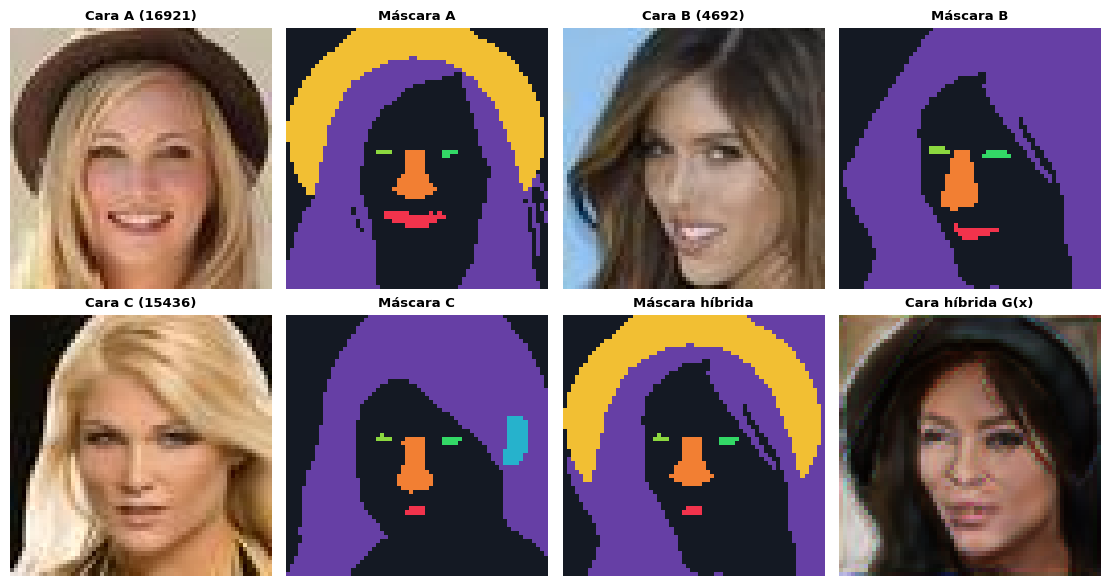

(array([[[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [1., 0., 0., ..., 0., 0., 0.],
         [1., 0., 0., ..., 0., 0., 0.],
         [1., 0., 0., ..., 0., 0., 0.]],
 
        [[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [1., 0., 0., ..., 0., 0., 0.],
         [1., 0., 0., ..., 0., 0., 0.],
         [1., 0., 0., ..., 0., 0., 0.]],
 
        [[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [1., 0., 0., ..., 0., 0., 0.],
         [1., 0., 0., ..., 0., 0., 0.],
         [1., 0., 0., ..., 0., 0., 0.]],
 
        ...,
 
        [[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [1., 0., 0., ..., 0., 0., 0.],
         [1., 0., 0., ..., 0., 0., 0.],


In [103]:
# Mezclar 3 personas (nariz de B + ojos y boca de C sobre A):

mix_faces(
    idx_a=94,
    idx_b=130,
    attrs_from_b=["hair"],
    idx_c=250,
    attrs_from_c=["l_eye", "r_eye", "mouth"],
)

---

## **7. Evaluación cuantitativa:**

Evaluamos el modelo final sobre el conjunto completo de **`3.000` muestras**:

- **Evaluación emparejada (`3.000`):** `L1 (MAE)` (en escala `[0, 1]`, mitad del `L1` en `[-1, 1]` de las curvas de entrenamiento), `1 - SSIM` y `FID emparejado (3k)` de $G(x_{\text{test}})$ frente a $y_{\text{test}}$.
- **Evaluación en caras nuevas (`3.000`):** sintetizamos `3.000` caras nuevas combinando máscaras híbridas de pares aleatorios de `test` (`sample_pairs(..., contrast=False)`) y calculamos su `FID caras nuevas (3k)` frente a las `3.000` caras reales de `test`.
- **Suelo real-vs-real (`val` vs `test`, `3.000`):** FID entre dos particiones reales distintas, que marca la cota inferior alcanzable a este tamaño muestral.

In [ ]:
def evaluate_generator() -> pd.DataFrame:
    y_test_01 = denormalize_image(y_test)
    y_val_01 = denormalize_image(y_val)
    paired_01 = denormalize_image(y_test_pred)

    l1_mae = float(np.mean(np.abs(y_test_01 - paired_01)))
    one_minus_ssim = 1.0 - float(
        tf.reduce_mean(
            tf.image.ssim(
                tf.convert_to_tensor(y_test_01, dtype=tf.float32),
                tf.convert_to_tensor(paired_01, dtype=tf.float32),
                max_val=1.0,
            )
        ).numpy()
    )

    feats_real_test = extract_inception_features(y_test_01)
    feats_real_val = extract_inception_features(y_val_01)
    feats_paired = extract_inception_features(paired_01)

    fid_paired = compute_fid_from_features(feats_real_test, feats_paired)
    floor_fid = compute_fid_from_features(feats_real_test, feats_real_val)

    new_pairs = sample_pairs(
        n_pairs=NEW_FACES_N, attrs_options=DEFAULT_ATTRS_OPTIONS, split="test", seed=SEED + 2025, contrast=False
    )
    x_new_masks = np.stack([hybridize_masks(x_test[ia], x_test[ib], attrs) for ia, ib, attrs in new_pairs], axis=0)
    new_faces_01 = denormalize_image(generate(x_new_masks))
    feats_new = extract_inception_features(new_faces_01)
    fid_new = compute_fid_from_features(feats_real_test, feats_new)

    rows = [
        {
            "Modelo": NOTEBOOK_NAME,
            "L1 (MAE)": f"{l1_mae:.4f}",
            "1 - SSIM": f"{one_minus_ssim:.4f}",
            "FID emparejado (3k)": f"{fid_paired:.2f}",
            "FID caras nuevas (3k)": f"{fid_new:.2f}",
        },
        {
            "Modelo": "Suelo real (val vs test)",
            "L1 (MAE)": "-",
            "1 - SSIM": "-",
            "FID emparejado (3k)": f"{floor_fid:.2f}",
            "FID caras nuevas (3k)": f"{floor_fid:.2f}",
        },
    ]
    return pd.DataFrame(rows)


metrics_df = evaluate_generator()
metrics_df.to_csv(METRICS_CSV_PATH, index=False)
print(f"Tabla final guardada en {METRICS_CSV_PATH.name}:")
display(metrics_df)

Tabla final guardada en gan_generator_metrics.csv:


,Modelo,L1 (MAE),1 - SSIM,FID emparejado (3k),FID caras nuevas (3k)
0,gan_generator,0.2068,0.5903,48.15,49.40
1,Suelo real (val vs test),-,-,7.63,7.63


## **8. Conclusiones**

* **Rendimiento cuantitativo en `test` (3.000 muestras):** el modelo final obtiene un **FID de `48.15`**, un `L1 (MAE)` de **`0.2068`** y un `1 - SSIM` de **`0.5903`**. Aunque existe distancia respecto al **suelo real (`7.63`)** medido entre particiones reales (`val` vs `test`), el resultado es consistente para un generador entrenado desde cero a `64x64` únicamente a partir de 8 máscaras binarias.

* **Generalización en caras nuevas:** al generar **3.000 caras nuevas** combinando partes de máscaras de distintos sujetos, el modelo consigue un **FID de `49.40`**, a solo **`1.25` puntos** del FID emparejado (`48.15`). Esta diferencia mínima confirma que el generador no se limita a memorizar caras vistas, sino que mezcla de forma coherente los rasgos faciales. Con tan poca diferencia, este es nuestro techo con el modelo actual.

### **Limitaciones y trabajo futuro**

* **Generación determinista:** al no disponer de un *encoder* de estilo ni de variación latente, una máscara fija produce siempre la misma cara. Extender el modelo hacia otras arquitecturas como **BicycleGAN** permitiría generar varias apariencias realistas desde una misma máscara.

* **Resolución y nitidez:** la resolución `64x64` limita la definición de detalles finos en la cara. Escalar la red a `128x128` sería el siguiente paso natural si tuviésemos suficientes recursos y datos y quisiésemos seguir utilizando esta arquitectua.

* **Exploración de pérdidas adicionales:** `1 - SSIM` podría tener un efecto dentro de la pérdida, al igual que ampliar la búsqueda de pesos con varias semillas.

En cualquier caso, parece que si queremos mejorar estos resultados debemos probar otras arquitecturas.
